# 02 Mrežna i korelaciona analiza

Ulaz: `data/interim/dataset.parquet` (14.156 oglasa), rezultat notebooka
`01_ekstrakcija.ipynb`.

Redosled:

1. kanonizacija naziva tehnologija
2. co-occurrence graf i detekcija zajednica
3. metrike centralnosti
4. korelaciona analiza, plate i ton oglasa

## 1. Podešavanje i učitavanje

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns

INTERIM = Path("data/interim")
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white",
                     "font.size": 10, "axes.titlesize": 13})

dataset = pd.read_parquet(INTERIM / "dataset.parquet")
print(f"Učitano: {len(dataset):,} oglasa, {len(dataset.columns)} kolona")
print(f"Kolone: {list(dataset.columns)}")

Učitano: 14,156 oglasa, 17 kolona
Kolone: ['job_id', 'is_it_role', 'role_family', 'tech_stack', 'vibe_score', 'red_flags', 'green_flags', 'title', 'company_name', 'location', 'views', 'applies', 'formatted_experience_level', 'remote_allowed', 'formatted_work_type', 'godisnja_plata', 'pay_period']


### Radni skup

Analiza se radi nad oglasima koje je jezički model potvrdio kao IT
(`is_it_role = True`). Ne-IT oglasi ostaju u fajlu i služe kao kontrolna grupa
u korelacionoj analizi, gde se porede tehničke i netehničke pozicije.

In [2]:
it = dataset[dataset["is_it_role"]].copy()
print(f"IT oglasa      : {len(it):,}")
print(f"ne-IT (kontrola): {len(dataset) - len(it):,}")
print(f"\nsa platom      : {it['godisnja_plata'].between(20_000, 500_000).sum():,}")
print(f"sa views+applies: {(it['views'].notna() & it['applies'].notna()).sum():,}")
print(f"sa seniority   : {it['formatted_experience_level'].notna().sum():,}")

IT oglasa      : 11,713
ne-IT (kontrola): 2,443

sa platom      : 3,411
sa views+applies: 5,118
sa seniority   : 8,447


## 2. Problem: isti pojam pod više imena

Pre svakog brojanja, pregled stanja naziva tehnologija koje je model izvukao.

In [3]:
sve_pojave = [str(t).strip() for lista in it["tech_stack"] for t in lista]
sirovi = Counter(sve_pojave)

print(f"Ukupno pojava tehnologija : {len(sve_pojave):,}")
print(f"Jedinstvenih naziva       : {len(sirovi):,}")
print(f"Prosečno po oglasu        : {len(sve_pojave)/len(it):.2f}")

samo_jednom = sum(1 for n in sirovi.values() if n == 1)
print(f"\nNaziva koji se javljaju samo jednom: {samo_jednom:,} "
      f"({samo_jednom/len(sirovi)*100:.0f}% jedinstvenih naziva)")

Ukupno pojava tehnologija : 85,999
Jedinstvenih naziva       : 11,541
Prosečno po oglasu        : 7.34

Naziva koji se javljaju samo jednom: 6,868 (60% jedinstvenih naziva)


In [4]:
def varijante(pojam: str, koliko: int = 7):
    nadjene = sorted((t for t in sirovi if pojam in t.lower()),
                     key=lambda x: -sirovi[x])[:koliko]
    return [(t, sirovi[t]) for t in nadjene]

for pojam in ["node", "react", "postgres", "javascript", ".net", "c++", "google cloud"]:
    print(f"{pojam:14} {varijante(pojam)}")

node           [('Node.js', 244), ('NodeJS', 124), ('Node', 83), ('Node.JS', 30), ('Node JS', 10), ('Nodejs', 9), ('NodeJs', 9)]
react          [('React', 671), ('ReactJS', 82), ('React Native', 69), ('React.js', 45), ('React JS', 7), ('React Testing Library', 6), ('React.JS', 4)]
postgres       [('PostgreSQL', 257), ('Postgres', 166), ('Postgresql', 6), ('Azure PostgreSQL', 5), ('PostGres', 5), ('PostGreSQL', 4), ('RDS Postgres', 4)]
javascript     [('JavaScript', 1141), ('Javascript', 109), ('javascript', 8), ('JavaScript/jQuery', 2), ('HTML/CSS/JavaScript', 2), ('JavaScript/TypeScript', 2), ('ES6+ JavaScript', 1)]
.net           [('.NET', 373), ('.NET Core', 110), ('ASP.NET', 105), ('.Net', 95), ('ASP.NET MVC', 39), ('.Net Core', 38), ('VB.NET', 23)]
c++            [('C++', 598), ('C/C++', 122), ('C/C++14', 2), ('C++11', 2), ('C++17', 2), ('Embedded C++', 1), ('C/CVI/C++', 1)]
google cloud   [('Google Cloud', 159), ('Google Cloud Platform', 59), ('Google Cloud Functions', 4), ('Goog

### Varijante istog naziva

`Node.js` se pojavljuje pod sedam pravopisa:

```
Node.js 244, NodeJS 124, Node 83, Node.JS 30, Node JS 10, Nodejs 9, NodeJs 9
```

Ukupno 509 pojava, rasutih tako da nijedna varijanta sama ne odražava stvarnu
zastupljenost. U grafu bi to bilo sedam odvojenih čvorova, svaki sa slabijim
vezama nego što tehnologija stvarno ima.

Ne spaja se sve što liči. U istoj listi su i:

```
React 671, ReactJS 82, React.js 45     ista tehnologija
React Native 69                        druga tehnologija, mobilni razvoj

.NET 373, .Net 95                      ista
ASP.NET 105, .NET Core 110, VB.NET 23  srodne, ali ne iste
```

Spajaju se pravopisne varijante istog imena. Pojmovi koji označavaju različit
proizvod se ne spajaju, čak i kad dele koren imena.

### Redosled: kanonizacija ide pre brojanja

Nazivi se svode na kanonski oblik nad tekstom, pre nego što se bilo šta broji.
Spajanje nad gotovim grafom, preko `nx.relabel_nodes`, nosi tri problema:

1. `REACT` i `REACTJS` se broje kao odvojene tehnologije pri računanju
   frekvencija i težina ivica, pa svaki pojedinačno može pasti ispod praga i
   nestati iz grafa
2. kada `relabel_nodes` spoji dva postojeća čvora, težine ivica se prepisuju,
   a ne sabiraju, pa su težine u finalnom grafu pogrešne za svaki sinonimski par
3. kolona sa nazivima u tabeli i ključevi podele na klastere razilaze se po
   obliku naziva, pa pretraga tehnologije u podeli promašuje, a broj pokrivenih
   oblasti po oglasu izlazi sistematski manji

## 3. Kanonizacija

Funkcija radi u tri koraka, tim redom:

```
"Node.JS (v18)"        -> pravopis -> "NODE.JS"              -> sinonim -> "NODE.JS"  -> zadrži
"Amazon Web Services"  -> pravopis -> "AMAZON WEB SERVICES"  -> sinonim -> "AWS"      -> zadrži
"Computer Science"     -> pravopis -> "COMPUTER SCIENCE"     -> nije tehnologija      -> izbaci
```

### Korak 1: pravopis

Velika slova, uklanjanje zagrada, verzije na kraju (`Java 8` daje `JAVA`) i
generičkih sufiksa (`Python scripting` daje `PYTHON`).

Verzija se briše samo kad joj prethodi razmak (`\s+\d+`). Bez tog uslova bi
`S3` postalo `S`, a `EC2` bi postalo `EC`.

### Korak 2: sinonimi, iz ručne tabele

Mehaničko pravilo "obriši interpunkciju i spoji što ostane" nad ovim podacima
daje:

```
C# (815) + C++ (598) + C (236) + C+ (2)   jedan čvor
```

Tri različita jezika i 1.651 pojava spojenih u jedan čvor. Zato mehaničko
pravilo nije u kodu, nego je poslužilo samo da izvuče kandidate, a tabela ispod
je ručno proverena.

Tabela spaja pravopisne varijante i poznate aliase istog proizvoda: `NodeJS` i
`Node.js`, `Golang` i `Go`, `K8s` i `Kubernetes`. Ne spaja različite proizvode
koji dele koren imena: `React` i `React Native`, `.NET` i `ASP.NET`, `C` i `C++`.

### Korak 3: izbacivanje onoga što nije tehnologija

Lista je kratka jer je posao većinom obavljen ranije. Oznaka `is_it_role` je
uklonila ne-IT oglase, a sa njima i pojmove poput `HVAC SYSTEMS`, `GENERATORS`
i `OSCILLOSCOPES`.

Ostaju tri kategorije: imena proizvođača bez proizvoda (`MICROSOFT`), čiste
generičke kategorije (`CLOUD`, `API`) i kancelarijski alati (`MICROSOFT OFFICE`).

Arhitektonski pojmovi se zadržavaju (`REST`, `SOAP`, `MICROSERVICES`, `NOSQL`),
jer su to veštine koje se traže, a ne šum.

In [5]:
# --- korak 2: sinonimi (kanonski oblik desno) ---
SINONIMI = {
    # pravopisne varijante
    "JAVA SCRIPT": "JAVASCRIPT",   "TYPE SCRIPT": "TYPESCRIPT",
    "POWERBI": "POWER BI",         "POWER-BI": "POWER BI",
    "SQLSERVER": "SQL SERVER",     "SQL-SERVER": "SQL SERVER",
    "CICD": "CI/CD",               "CI-CD": "CI/CD",            "CI CD": "CI/CD",
    "ACTIVEDIRECTORY": "ACTIVE DIRECTORY",
    "SERVICE NOW": "SERVICENOW",   "SERVICE-NOW": "SERVICENOW",
    "SPRINGBOOT": "SPRING BOOT",   "SPRING-BOOT": "SPRING BOOT",
    "VM WARE": "VMWARE",           "DATA BRICKS": "DATABRICKS",
    "AZURE DEV OPS": "AZURE DEVOPS", "AZUREDEVOPS": "AZURE DEVOPS",
    "NO-SQL": "NOSQL",             "NO SQL": "NOSQL",
    "MONGO DB": "MONGODB",         "GOOGLECLOUD": "GOOGLE CLOUD",
    "POSTGRE SQL": "POSTGRESQL",   "NET": ".NET",

    # varijante imena istog proizvoda
    "NODEJS": "NODE.JS",   "NODE JS": "NODE.JS",   "NODE": "NODE.JS",
    "REACTJS": "REACT",    "REACT.JS": "REACT",    "REACT JS": "REACT",
    "POSTGRES": "POSTGRESQL",
    "MONGO": "MONGODB",
    "ELASTIC": "ELASTICSEARCH",
    "HTML5": "HTML",       "CSS3": "CSS",
    "C/C++": "C++",

    # poznati aliasi
    "GOLANG": "GO",
    "K8S": "KUBERNETES",
    "JS": "JAVASCRIPT",    "TS": "TYPESCRIPT",
    "AMAZON WEB SERVICES": "AWS",
    "GOOGLE CLOUD": "GCP", "GOOGLE CLOUD PLATFORM": "GCP",
    "MICROSOFT AZURE": "AZURE", "AZURE CLOUD": "AZURE",
    "MSSQL": "SQL SERVER", "MS SQL": "SQL SERVER",
    "MICROSOFT SQL SERVER": "SQL SERVER",
    "DOTNET": ".NET",
}

# --- korak 3: nije tehnologija ---
NIJE_TEHNOLOGIJA = {
    # proizvođač bez proizvoda
    "MICROSOFT", "GOOGLE", "AMAZON", "ORACLE CORPORATION", "IBM",
    # generičke kategorije
    "CLOUD", "API", "APIS", "DEVOPS", "DATABASE", "DATABASES", "SOFTWARE",
    "PROGRAMMING", "SCRIPTING", "FRONTEND", "BACKEND", "FULL STACK",
    "OPERATING SYSTEM", "OPERATING SYSTEMS", "NETWORKING", "SECURITY",
    "AUTOMATION", "TESTING", "MONITORING", "VIRTUALIZATION",
    # kancelarijski alati
    "MICROSOFT OFFICE", "OFFICE", "MS OFFICE", "MICROSOFT OFFICE SUITE",
    "WORD", "POWERPOINT", "OUTLOOK", "VISIO", "MICROSOFT WORD",
    # obrazovanje i meke veštine
    "COMPUTER SCIENCE", "SOFTWARE ENGINEERING", "INFORMATION TECHNOLOGY",
    "COMPUTER ENGINEERING", "DEGREE", "BACHELOR", "COMMUNICATION",
    "TEAMWORK", "PROBLEM SOLVING", "AGILE", "SCRUM", "KANBAN", "SAFE",
    "DOCUMENTATION", "TROUBLESHOOTING", "DEBUGGING", "CODE REVIEW",
    "BEST PRACTICES", "MENTORING",
}

# Tokeni koji su zapravo DVE tehnologije. Opšte pravilo "razdvoji po /" bi
# pokvarilo CI/CD, TCP/IP, PL/SQL i IDS/IPS, pa lista mora biti izričita.
RASTAVI = {
    "HTML/CSS": ["HTML", "CSS"],
    "HTML/CSS/JAVASCRIPT": ["HTML", "CSS", "JAVASCRIPT"],
    "JAVASCRIPT/TYPESCRIPT": ["JAVASCRIPT", "TYPESCRIPT"],
}

_ZAGRADE = re.compile(r"\s*\([^)]*\)")
_VERZIJA = re.compile(r"\s+\d+(\.\d+)*$")       # samo uz razmak: "JAVA 8" da, "S3" ne
_SUFIKS  = re.compile(r"\s+(FRAMEWORK|LIBRARY|PLATFORM|SERVICE|TOOL|"
                      r"TECHNOLOG(Y|IES)|SCRIPTING|CERTIFIED|CERTIFICATION)S?$")


def canonicalize(naziv: str) -> str | None:
    """Sirov naziv tehnologije -> kanonski oblik, ili None ako nije tehnologija."""
    t = re.sub(r"\s+", " ", str(naziv).strip().upper())

    # Tabela se gleda i PRE normalizacije: regex za sufikse bi inače pojeo
    # "SERVICES" iz "AMAZON WEB SERVICES" i unos za AWS ne bi opalio.
    if t in SINONIMI:
        return SINONIMI[t]

    t = _ZAGRADE.sub("", t)
    t = _VERZIJA.sub("", t)
    t = _SUFIKS.sub("", t)
    t = re.sub(r"\s+", " ", t).strip()

    t = SINONIMI.get(t, t)

    if not t or t in NIJE_TEHNOLOGIJA or len(t) > 40:
        return None
    return t


for probe in ["Node.JS (v18)", "NodeJS", "Java 8", "Python scripting", "AWS (S3, EC2)",
              "S3", "Amazon Web Services", "Computer Science", "C++", "C#", "C",
              "React Native", "ReactJS", "Golang", "PostGreSQL"]:
    print(f"   {probe:24} -> {canonicalize(probe)}")


def kanonizuj_listu(lista) -> list[str]:
    """Cela lista iz jednog oglasa -> skup kanonskih naziva, bez ponavljanja."""
    izlaz = set()
    for sirov in lista:
        t = re.sub(r"\s+", " ", str(sirov).strip().upper())
        if t in RASTAVI:
            izlaz.update(RASTAVI[t])
            continue
        k = canonicalize(sirov)
        if k:
            izlaz.add(k)
    return sorted(izlaz)

   Node.JS (v18)            -> NODE.JS
   NodeJS                   -> NODE.JS
   Java 8                   -> JAVA
   Python scripting         -> PYTHON
   AWS (S3, EC2)            -> AWS
   S3                       -> S3
   Amazon Web Services      -> AWS
   Computer Science         -> None
   C++                      -> C++
   C#                       -> C#
   C                        -> C
   React Native             -> REACT NATIVE
   ReactJS                  -> REACT
   Golang                   -> GO
   PostGreSQL               -> POSTGRESQL


### Primena i efekat

In [6]:
dataset["tech"] = dataset["tech_stack"].apply(kanonizuj_listu)
it = dataset[dataset["is_it_role"]].copy()

pre  = Counter(str(t).strip() for lista in it["tech_stack"] for t in lista)
posle = Counter(t for lista in it["tech"] for t in lista)

print(f"jedinstvenih naziva : {len(pre):>7,}  ->  {len(posle):>7,}"
      f"   ({(1-len(posle)/len(pre))*100:.0f}% manje)")
print(f"ukupno pojava       : {sum(pre.values()):>7,}  ->  {sum(posle.values()):>7,}")
print(f"po oglasu           : {sum(pre.values())/len(it):>7.2f}  ->  {sum(posle.values())/len(it):>7.2f}")
print(f"oglasa bez ijedne   : {(it['tech_stack'].apply(len)==0).sum():>7,}  ->  "
      f"{(it['tech'].apply(len)==0).sum():>7,}")

print("\nTop 15 posle kanonizacije:")
for t, n in posle.most_common(15):
    print(f"   {t:22} {n:5}")

jedinstvenih naziva :  11,541  ->    9,852   (15% manje)
ukupno pojava       :  85,999  ->   83,602
po oglasu           :    7.34  ->     7.14
oglasa bez ijedne   :   1,041  ->    1,080

Top 15 posle kanonizacije:
   PYTHON                  3125
   SQL                     2360
   AWS                     2211
   JAVA                    1905
   AZURE                   1717
   JAVASCRIPT              1293
   KUBERNETES              1039
   GIT                     1024
   DOCKER                   941
   LINUX                    846
   REACT                    815
   C#                       815
   GCP                      763
   C++                      720
   JENKINS                  672


### Kontrola: šta je spojeno

Provera da nije spojeno nešto što ne sme. Za svaki kanonski naziv slede svi
sirovi oblici koji su u njega ušli.

In [7]:
spojeno = {}
for sirov in pre:
    kan = canonicalize(sirov)
    if kan:
        spojeno.setdefault(kan, []).append(sirov)

visestruki = {k: v for k, v in spojeno.items() if len(v) > 1}
print(f"Kanonskih naziva nastalih spajanjem više oblika: {len(visestruki):,}\n")

for kan in sorted(visestruki, key=lambda k: -posle[k])[:12]:
    oblici = sorted(visestruki[kan], key=lambda s: -pre[s])[:6]
    print(f"   {kan:16} ({posle[kan]:4}) <- {[(o, pre[o]) for o in oblici]}")

print("\nProvera da NISU spojeni različiti proizvodi:")
for a in ["C", "C#", "C++", "REACT", "REACT NATIVE", ".NET", "ASP.NET", "VB.NET"]:
    print(f"   {a:14} -> {canonicalize(a):14} ({posle.get(canonicalize(a), 0)} pojava)")

Kanonskih naziva nastalih spajanjem više oblika: 1,164

   PYTHON           (3125) <- [('Python', 3080), ('python', 44), ('PYTHON', 1)]
   SQL              (2360) <- [('SQL', 2361), ('sql', 1)]
   AWS              (2211) <- [('AWS', 2204), ('Amazon Web Services', 4), ('Aws', 2), ('AWS Services', 1), ('aws', 1)]
   JAVA             (1905) <- [('Java', 1883), ('JAVA', 17), ('java', 3), ('Java 8', 3), ('Java 11', 1), ('JAVA 8', 1)]
   AZURE            (1717) <- [('Azure', 1635), ('Microsoft Azure', 50), ('Azure Cloud', 28), ('Azure Cloud Services', 3), ('Azure Services', 2), ('Azure services', 2)]
   JAVASCRIPT       (1293) <- [('JavaScript', 1141), ('Javascript', 109), ('JS', 26), ('javascript', 8), ('Java Script', 5)]
   KUBERNETES       (1039) <- [('Kubernetes', 1014), ('K8s', 16), ('k8s', 6), ('K8S', 5)]
   GIT              (1024) <- [('Git', 800), ('GIT', 162), ('git', 61), ('GiT', 1)]
   DOCKER           ( 941) <- [('Docker', 940), ('docker', 1)]
   LINUX            ( 846) <- [('Lin

### Pregled ekstrakcije

Kratak pogled na to šta je model izvukao: raspodela zastavica i najčešći pojmovi.

Grafikon tehnologija koristi kanonizovane nazive, pa `Node.js`, `NodeJS` i
`Node` stoje kao jedna stavka.

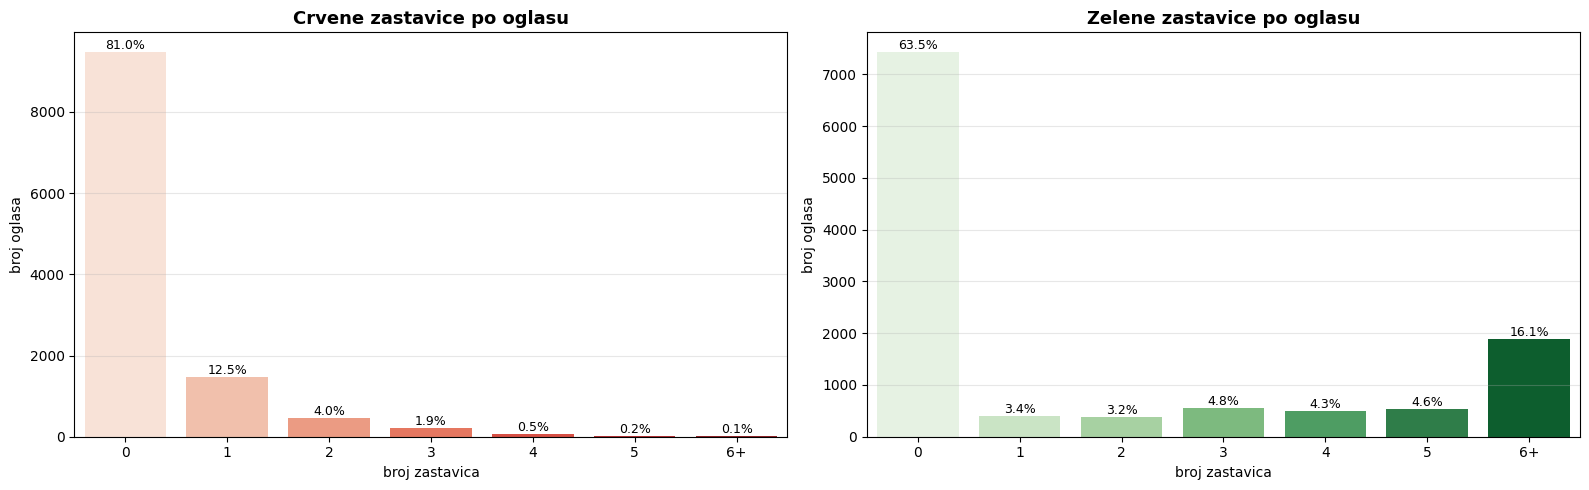

oglasa bez ijedne crvene zastavice : 81.0%
oglasa bez ijedne zelene zastavice : 63.5%
oglasa sa 3+ crvene ('toksični')   : 2.5%


In [8]:
pregled = dataset[dataset["is_it_role"]].copy()
pregled["n_red"] = pregled["red_flags"].apply(len)
pregled["n_green"] = pregled["green_flags"].apply(len)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, kolona, naslov, paleta in [
    (axes[0], "n_red", "Crvene zastavice", "Reds"),
    (axes[1], "n_green", "Zelene zastavice", "Greens"),
]:
    podaci = pregled[kolona].clip(upper=6)
    broj = podaci.value_counts().sort_index()
    oznake = [str(int(i)) if i < 6 else "6+" for i in broj.index]
    sns.barplot(x=oznake, y=broj.values, hue=oznake, palette=paleta,
                legend=False, ax=ax)
    for i, v in enumerate(broj.values):
        ax.annotate(f"{v/len(pregled)*100:.1f}%", (i, v),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{naslov} po oglasu", fontsize=13, fontweight="bold")
    ax.set_xlabel("broj zastavica"); ax.set_ylabel("broj oglasa")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIG / "pregled_zastavice.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"oglasa bez ijedne crvene zastavice : {(pregled['n_red'] == 0).mean()*100:.1f}%")
print(f"oglasa bez ijedne zelene zastavice : {(pregled['n_green'] == 0).mean()*100:.1f}%")
print(f"oglasa sa 3+ crvene ('toksični')   : {(pregled['n_red'] >= 3).mean()*100:.1f}%")

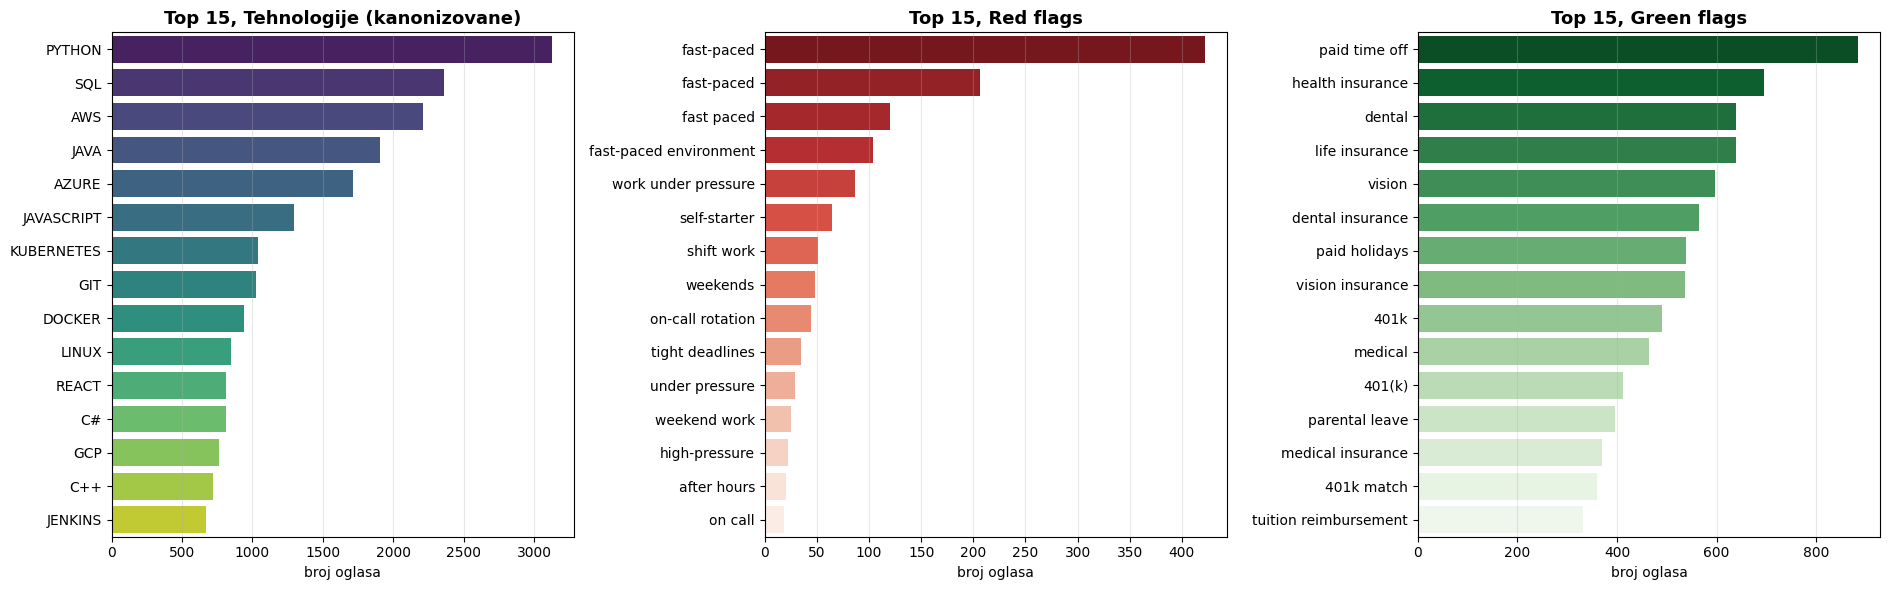

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

prikazi = [
    ("tech", "Tehnologije (kanonizovane)", "viridis", False),
    ("red_flags", "Red flags", "Reds_r", True),
    ("green_flags", "Green flags", "Greens_r", True),
]

for ax, (kolona, naslov, paleta, malim_slovima) in zip(axes, prikazi):
    pojmovi = [str(t).lower() if malim_slovima else str(t)
               for lista in pregled[kolona] for t in lista]
    najcesci = Counter(pojmovi).most_common(15)
    imena, brojevi = zip(*najcesci)
    sns.barplot(x=list(brojevi), y=list(imena), hue=list(imena),
                palette=paleta, legend=False, ax=ax)
    ax.set_title(f"Top 15, {naslov}", fontsize=13, fontweight="bold")
    ax.set_xlabel("broj oglasa"); ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(FIG / "pregled_pojmovi.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Co-occurrence graf

Čvor je tehnologija, ivica postoji kad se dve tehnologije javljaju u istom
oglasu. Oglas sa `[Python, AWS, Docker]` doprinosi trima parovima:

```
Python-AWS, Python-Docker, AWS-Docker
```

Ista struktura, oglas kao korpa tehnologija, ulaz je i za Apriori u
`03_preporuka.ipynb`.

### Pragovi moraju biti relativni

Apsolutni prag je vezan za veličinu uzorka: prag od 5 oglasa nad 1.460 oglasa i
isti taj prag nad 11.713 oglasa propuštaju bitno različitu količinu šuma, jer se
retka kombinacija koja se u malom uzorku javi 2 puta u velikom javi 15 puta.

Pragovi su zato izraženi kao udeo oglasa, da rezultat ne zavisi od toga koliko
je oglasa ekstrahovano.

In [10]:
from itertools import combinations

it = dataset[dataset["is_it_role"]].copy()
N = len(it)

frekvencija = Counter(t for lista in it["tech"] for t in lista)
parovi = Counter()
for lista in it["tech"]:
    parovi.update(combinations(sorted(lista), 2))

print(f"oglasa                : {N:,}")
print(f"jedinstvenih tehnologija: {len(frekvencija):,}")
print(f"jedinstvenih parova   : {len(parovi):,}")
print(f"\napsolutni prag od 5 oglasa nad uzorkom od 1.460: freq>=5 = 0.34%, ivica>=6 = 0.41%")
print(f"isti udeo na {N:,} oglasa   : freq>={round(N*0.0034)}, ivica>={round(N*0.0041)}")

oglasa                : 11,713
jedinstvenih tehnologija: 9,852
jedinstvenih parova   : 177,237

apsolutni prag od 5 oglasa nad uzorkom od 1.460: freq>=5 = 0.34%, ivica>=6 = 0.41%
isti udeo na 11,713 oglasa   : freq>=40, ivica>=48


### Kako prag menja graf

In [11]:
import numpy as np


def gradi_graf(prag_cvora: float, prag_ivice: float, tezina="lift") -> nx.Graph:
    """Prag se zadaje kao UDEO oglasa, ne kao apsolutan broj."""
    mf, me = max(2, round(N * prag_cvora)), max(2, round(N * prag_ivice))
    cvorovi = {t for t, n in frekvencija.items() if n >= mf}

    G = nx.Graph()
    for (a, b), w in parovi.items():
        if w >= me and a in cvorovi and b in cvorovi:
            lift = (w * N) / (frekvencija[a] * frekvencija[b])
            G.add_edge(a, b, weight=lift if tezina == "lift" else w, support=w, lift=lift)
    G.remove_nodes_from(list(nx.isolates(G)))
    nx.set_node_attributes(G, {n: frekvencija[n] for n in G}, "frekvencija")
    return G



PONAVLJANJA_LOUVAIN = 100   # koliko puta se Louvain pokreće da bi se izabrala tipična podela


def louvain(G: nx.Graph, seed: int = 42) -> list[set]:
    """Louvain nezavisan od redosleda kojim je graf građen.

    Rezultat networkx-ovog Louvain-a zavisi od seed-a, ali i od redosleda čvorova i
    grana, a redosled skupova sa nazivima Python menja od pokretanja do pokretanja.
    Zato se graf gradi iznova sa sortiranim čvorovima i granama i celobrojnim
    oznakama, a posle se oznake vraćaju u nazive.
    """
    cvorovi = sorted(G.nodes)
    broj = {n: i for i, n in enumerate(cvorovi)}
    H = nx.Graph()
    H.add_nodes_from(range(len(cvorovi)))
    H.add_weighted_edges_from(sorted((min(broj[u], broj[v]), max(broj[u], broj[v]), d["weight"])
                                     for u, v, d in G.edges(data=True)))
    return [{cvorovi[i] for i in z} for z in nx.community.louvain_communities(H, weight="weight", seed=seed)]


def oznake_podele(podela: list[set], cvorovi: list[str]) -> list[int]:
    grupa = {n: i for i, z in enumerate(podela) for n in z}
    return [grupa[n] for n in cvorovi]


def tipicna_podela(G: nx.Graph, pokretanja: int = 100):
    """Louvain sa više seed-ova; bira se podela koja je u proseku najsličnija svim ostalima."""
    from sklearn.metrics import adjusted_rand_score
    cvorovi = sorted(G.nodes)
    podele = [louvain(G, seed) for seed in range(pokretanja)]
    oznake = [oznake_podele(p, cvorovi) for p in podele]
    slicnost = np.eye(pokretanja)
    for a in range(pokretanja):
        for b in range(a + 1, pokretanja):
            slicnost[a, b] = slicnost[b, a] = adjusted_rand_score(oznake[a], oznake[b])
    izabrana = int(slicnost.mean(axis=1).argmax())
    return podele[izabrana], podele, slicnost, izabrana


redovi = []
for pc, pi in [(0.002, 0.002), (0.003, 0.003), (0.0034, 0.0041),
               (0.005, 0.005), (0.01, 0.01), (0.02, 0.02)]:
    G = gradi_graf(pc, pi)
    com = tipicna_podela(G, PONAVLJANJA_LOUVAIN)[0]
    redovi.append({
        "prag čvora %": pc * 100, "prag ivice %": pi * 100,
        "čvorova": G.number_of_nodes(), "ivica": G.number_of_edges(),
        "gustina": round(nx.density(G), 3),
        "klastera": len(com),
        "Q": round(nx.community.modularity(G, com), 3),
    })
print(pd.DataFrame(redovi).to_string(index=False))

 prag čvora %  prag ivice %  čvorova  ivica  gustina  klastera     Q
         0.20          0.20      270   2078    0.057        15 0.690
         0.30          0.30      189   1260    0.071        14 0.640
         0.34          0.41      155    842    0.071        14 0.652
         0.50          0.50      122    653    0.088        12 0.577
         1.00          1.00       67    253    0.114         9 0.515
         2.00          2.00       34     81    0.144         5 0.512


In [12]:
# Zašto prag od 0,3 %: koje male oblasti nestaju pri višem pragu
for prag in (0.005, 0.01):
    granica = round(N * prag)
    ispod = [t for t in ["JCL", "VISUALFORCE", "JUNIPER", "RAILS", "COBOL", "BGP", "OSPF"] if frekvencija[t] < granica]
    print(f"prag {prag*100:.1f} % ({granica} oglasa): ispod granice {', '.join(ispod)}")
print(f"prag 0,2 % dodaje {gradi_graf(0.002, 0.002).number_of_nodes() - gradi_graf(0.003, 0.003).number_of_nodes()} "
      f"tehnologija, uz najmanje {round(N * 0.002)} oglasa po tehnologiji i paru")

prag 0.5 % (59 oglasa): ispod granice JCL, VISUALFORCE, JUNIPER, RAILS
prag 1.0 % (117 oglasa): ispod granice JCL, VISUALFORCE, JUNIPER, RAILS, COBOL, BGP, OSPF
prag 0,2 % dodaje 81 tehnologija, uz najmanje 23 oglasa po tehnologiji i paru


### Težina ivice: zašto ne sirov broj

Najjednostavnija težina je koliko puta se par javio zajedno. Ta mera nagrađuje
čestotu, a ne povezanost.

Python je u 3.125 oglasa. Zato je svaka ivica `Python-X` teška za bilo koje X,
uključujući tehnologije koje sa Pythonom nemaju veze osim što su obe česte. Graf
se skuplja oko habova, a detekcija zajednica ne može da razdvoji oblasti.

Težina je umesto toga lift, odnosno koliko puta češće se par javlja nego što bi
se javljao da su tehnologije nezavisne:

```
lift(a,b) = P(a i b) / (P(a) * P(b)) = c(a,b) * N / (c(a) * c(b))
```

`lift = 1` znači nezavisnost, `lift = 5` da se par javlja pet puta češće od
očekivanog. Deljenjem osnovnom čestotom `Python-Pandas` pobeđuje `Python-Excel`
iako je drugi par brojniji.

Lift favorizuje retke parove, ali je to ovde ograničeno time što par mora da
pređe prag podrške: obe tehnologije u najmanje 0,3 % oglasa i par u najmanje
0,3 % oglasa. Filtriranje ide po sirovom broju, težina po liftu.

Lift je i mera koju Apriori koristi u `03_preporuka.ipynb`, pa mreža i sistem
preporuke mere povezanost na isti način.

### Sirov broj naspram lifta

Sirov broj i lift ne mere istu stvar. Ako su dve tehnologije nezavisne,
očekivani broj zajedničkih pojavljivanja je

```
c(a,b) = c(a) * c(b) / N
```

Sirov broj dakle po konstrukciji sadrži popularnost obe tehnologije. Python i
AWS se javljaju zajedno 1.034 puta, ali bi se i pod nezavisnošću očekivalo 590,
pa je stvarna veza svega 1,75 puta jača od očekivane.

Pošto istraživačko pitanje glasi kako su tehnologije međusobno povezane, a ne
koliko se traže, mera treba da izražava vezu. Lift je opaženo podeljeno
očekivanim i radi tačno to.

Sirov broj nije neupotrebljiv, tri od njegova četiri najveća klastera su
smislena. Slabost mu je jedan rezidualni klaster u koji upada sve popularno što
nije cloud ni web:

```
sirov broj, 1. klaster (50):  PYTHON, SQL, C++, POWER BI, JIRA, TABLEAU,
                              R, SPARK, EXCEL, SNOWFLAKE
```

To nije tehnološka oblast nego ostatak. Lift ga razlaže na oblasti:

```
lift, 1. klaster (45):  PYTHON, AZURE, KUBERNETES, GIT, DOCKER, LINUX, GCP, C++
lift, 3. klaster (29):  SQL, POWER BI, TABLEAU, KAFKA, R, SPARK, EXCEL, SNOWFLAKE
lift, 6. klaster (16):  JAVA, SPRING BOOT, SPRING, MICROSERVICES, MAVEN, KOTLIN
```

Lift dakle daje finiju i koherentniju podelu, pre svega time što razlaže
rezidualnu grupu. Nije da sirov broj ne radi.

Protiv-argument. Modularnost već sadrži korekciju za popularnost, jer težinu ne
poredi sa nulom nego sa očekivanjem pod null modelom koji čuva stepene čvorova:

```
Q = (1/2m) * suma [ A_ij - k_i * k_j / 2m ] * delta(klaster_i, klaster_j)
                            očekivano po popularnosti
```

Taj član radi isto što i lift, pa bi se moglo tvrditi da Louvain sam koriguje.
Teorijski stoji, empirijski nije bilo dovoljno, jer je graf već filtriran
pragom pa stepeni u null modelu ne odgovaraju punom grafu, a modularnost ima
poznato ograničenje rezolucije.

Sirov broj je stabilniji, pošto je lift razlomak sa malim imeniocem, pa
`SNS-SQS` dobija 147 na osnovu 49 oglasa. I obim je stvarna informacija: za
savet šta učiti, `Python + AWS` je isplativije od `Python + Pandas` uprkos
slabijoj vezi. To pitanje, obim ili srodnost, ponovo se otvara u
`03_preporuka.ipynb`, gde se Apriori poredi sa baseline-om po popularnosti.

Zato se koriste obe mere, svaka na svom mestu:

```
prag ulaska    sirov broj  (par u >= 0,3% oglasa)   čuva obim
težina ivice   lift        (jačina veze)            meri srodnost
```

In [13]:
for ime in ["sirov broj", "lift"]:
    Gt = gradi_graf(0.003, 0.003, tezina="lift" if ime == "lift" else "broj")
    com = tipicna_podela(Gt, PONAVLJANJA_LOUVAIN)[0]
    print(f"{ime.upper():11}  {len(com):2} klastera   Q = {nx.community.modularity(Gt, com):.3f}")
    for z in sorted(com, key=len, reverse=True)[:4]:
        print(f"{'':13}({len(z):3}) {', '.join(sorted(z, key=lambda t: (-frekvencija[t], t))[:10])}")
    print()

SIROV BROJ    6 klastera   Q = 0.238
             ( 50) PYTHON, SQL, C++, POWER BI, JIRA, TABLEAU, R, SPARK, EXCEL, SNOWFLAKE
             ( 45) AWS, AZURE, KUBERNETES, DOCKER, GCP, JENKINS, TERRAFORM, ANSIBLE, GO, CI/CD
             ( 45) JAVASCRIPT, GIT, C#, REACT, HTML, SQL SERVER, ORACLE, CSS, ANGULAR, .NET
             ( 26) JAVA, KAFKA, SPRING BOOT, SPRING, MICROSERVICES, MAVEN, SELENIUM, DB2, REDIS, KOTLIN



LIFT         14 klastera   Q = 0.640
             ( 45) PYTHON, AZURE, KUBERNETES, GIT, DOCKER, LINUX, GCP, C++, JENKINS, TERRAFORM
             ( 43) JAVASCRIPT, C#, REACT, HTML, SQL SERVER, ORACLE, CSS, ANGULAR, .NET, NODE.JS
             ( 29) SQL, POWER BI, TABLEAU, KAFKA, R, SPARK, EXCEL, SNOWFLAKE, SCALA, SHAREPOINT
             ( 18) WINDOWS, ACTIVE DIRECTORY, SERVICENOW, VMWARE, CISCO, UNIX, WINDOWS SERVER, DNS, TCP/IP, VPN



> Ograda. Vrednosti `Q` iz dve različite sheme težina nisu strogo uporedive, jer
> modularnost zavisi od raspodele težina, pa 0,640 naspram 0,238 ne znači
> mehanički dvostruko bolju podelu. Argument za lift je pre svega tumačivost
> dobijenih klastera, uz to što lift po konstrukciji kontroliše osnovnu čestotu.
> Brojevi ispod se čitaju uz tu ogradu.

### Finalni graf

### Louvain: ponovljivost i tipična podela

Louvain ne daje uvek istu podelu. Rezultat zavisi od slučajnog redosleda kojim
algoritam obilazi čvorove (`seed`), a u biblioteci `networkx` i od redosleda
kojim je graf izgrađen. Drugi uzrok uklanja funkcija `louvain`, koja graf uvek
gradi istim redom.

Prvi uzrok je svojstvo algoritma. Umesto jednog pokretanja sa proizvoljno
izabranim seed-om, Louvain se pokreće 100 puta, a za dalji rad se bira podela
koja je u proseku najsličnija svim ostalima. Sličnost dve podele meri se
prilagođenim Randovim indeksom (ARI): 1 znači identične podele, 0 znači slaganje
na nivou slučajnosti.

Tako izabrana podela je tipičan ishod, a ne slučajan. Koliko je stabilna vidi se
u tabeli posle nje.

In [14]:
PRAG_CVORA = 0.003     # tehnologija mora biti u >=0.3% oglasa
PRAG_IVICE = 0.003     # par mora biti u >=0.3% oglasa

G = gradi_graf(PRAG_CVORA, PRAG_IVICE, tezina="lift")
zajednice, podele_louvain, slicnost_louvain, izabrana_louvain = tipicna_podela(G, PONAVLJANJA_LOUVAIN)

partition = {cvor: i for i, z in enumerate(zajednice) for cvor in z}
nx.set_node_attributes(G, partition, "community")
Q = nx.community.modularity(G, zajednice)

print(f"čvorova {G.number_of_nodes()} | ivica {G.number_of_edges()} | "
      f"gustina {nx.density(G):.3f} | klastera {len(zajednice)} | Q = {Q:.3f}")
print(f"prag: tehnologija u >={round(N*PRAG_CVORA)} oglasa, par u >={round(N*PRAG_IVICE)} oglasa\n")

for i, z in enumerate(sorted(zajednice, key=len, reverse=True), 1):
    clanovi = sorted(z, key=lambda t: (-frekvencija[t], t))
    print(f"{i:2}. ({len(z):3} teh) {', '.join(clanovi[:14])}"
          + (" ..." if len(clanovi) > 14 else ""))

assert set(partition) == set(G.nodes), "partition i graf se ne poklapaju"

čvorova 189 | ivica 1260 | gustina 0.071 | klastera 14 | Q = 0.640
prag: tehnologija u >=35 oglasa, par u >=35 oglasa

 1. ( 45 teh) PYTHON, AZURE, KUBERNETES, GIT, DOCKER, LINUX, GCP, C++, JENKINS, TERRAFORM, POWERSHELL, JIRA, ANSIBLE, GO ...
 2. ( 43 teh) JAVASCRIPT, C#, REACT, HTML, SQL SERVER, ORACLE, CSS, ANGULAR, .NET, NODE.JS, TYPESCRIPT, POSTGRESQL, REST, AZURE DEVOPS ...
 3. ( 29 teh) SQL, POWER BI, TABLEAU, KAFKA, R, SPARK, EXCEL, SNOWFLAKE, SCALA, SHAREPOINT, DATABRICKS, HADOOP, SAS, SSIS ...
 4. ( 18 teh) WINDOWS, ACTIVE DIRECTORY, SERVICENOW, VMWARE, CISCO, UNIX, WINDOWS SERVER, DNS, TCP/IP, VPN, PALO ALTO, DHCP, BGP, OSPF ...
 5. ( 18 teh) AWS, LAMBDA, S3, CLOUDFORMATION, DYNAMODB, REDSHIFT, IAM, EC2, CLOUDWATCH, RDS, API GATEWAY, ECS, SQS, GITHUB ACTIONS ...
 6. ( 16 teh) JAVA, SPRING BOOT, SPRING, MICROSERVICES, MAVEN, KOTLIN, HIBERNATE, JUNIT, J2EE, SWIFT, REST API, GRADLE, TOMCAT, CUCUMBER ...
 7. (  4 teh) SALESFORCE, APEX, LIGHTNING, VISUALFORCE
 8. (  3 teh) DB2, C

### Stabilnost podele

Za svaku tehnologiju meri se koliki deo ostalih članova njene grupe se u
prosečnom pokretanju nađe u istoj zajednici sa njom. Vrednost 1 znači da
tehnologija uvek ostaje sa svojom grupom; niska vrednost znači da je na granici
između dve oblasti.

In [15]:
van_dijagonale = slicnost_louvain[~np.eye(PONAVLJANJA_LOUVAIN, dtype=bool)]
broj_grupa = [len(p) for p in podele_louvain]
modularnosti = [nx.community.modularity(G, p) for p in podele_louvain]
print(f"{PONAVLJANJA_LOUVAIN} pokretanja Louvain-a:")
print(f"   broj grupa        {min(broj_grupa)}-{max(broj_grupa)}")
print(f"   grupa sa >=10 teh. {min(sum(len(z) >= 10 for z in p) for p in podele_louvain)}-"
      f"{max(sum(len(z) >= 10 for z in p) for p in podele_louvain)}")
print(f"   modularnost       {min(modularnosti):.3f}-{max(modularnosti):.3f}")
print(f"   ARI između pokretanja: medijana {np.median(van_dijagonale):.3f}, "
      f"od {van_dijagonale.min():.3f} do {van_dijagonale.max():.3f}")
print(f"   izabrana podela: prosečan ARI sa ostalima {slicnost_louvain[izabrana_louvain].mean():.3f}\n")

stabilnost_clanova = {}
for z in zajednice:
    for t in z:
        ostali = z - {t}
        if ostali:
            stabilnost_clanova[t] = float(np.mean(
                [len(next(x for x in p if t in x) & ostali) / len(ostali) for p in podele_louvain]))

redovi = []
for z in sorted(zajednice, key=len, reverse=True):
    if len(z) < 3:
        continue
    vrednosti = sorted((stabilnost_clanova[t], t) for t in z)
    redovi.append({
        "grupa": ", ".join(sorted(z, key=lambda t: (-frekvencija[t], t))[:3]),
        "tehnologija": len(z),
        "prosečna stabilnost": round(float(np.mean([v for v, _ in vrednosti])), 2),
        "stabilnih (>=0,9)": sum(v >= 0.9 for v, _ in vrednosti),
        "najlabavije": ", ".join(f"{t} {v:.2f}" for v, t in vrednosti[:3]),
    })
print(pd.DataFrame(redovi).to_string(index=False))

100 pokretanja Louvain-a:
   broj grupa        14-16
   grupa sa >=10 teh. 5-7
   modularnost       0.626-0.642
   ARI između pokretanja: medijana 0.783, od 0.428 do 1.000
   izabrana podela: prosečan ARI sa ostalima 0.833

                                grupa  tehnologija  prosečna stabilnost  stabilnih (>=0,9)                                      najlabavije
            PYTHON, AZURE, KUBERNETES           45                 0.74                  0        APACHE SPARK 0.45, PYTHON 0.45, SIEM 0.56
                JAVASCRIPT, C#, REACT           43                 0.94                 41    AZURE DEVOPS 0.54, NOSQL 0.59, CASSANDRA 0.93
               SQL, POWER BI, TABLEAU           29                 0.79                  0   DAX 0.65, POWER APPS 0.65, POWER AUTOMATE 0.65
WINDOWS, ACTIVE DIRECTORY, SERVICENOW           18                 0.87                  9            UNIX 0.56, SCCM 0.83, SERVICENOW 0.83
                      AWS, LAMBDA, S3           18                 0.94     

## 5. Metrike centralnosti

Zajednice kažu gde je tehnologija, centralnost kaže koliko je važna.

Degree centrality je popularnost, broj suseda podeljen brojem mogućih suseda.
Vrednost 0,601 znači da je tehnologija povezana sa 60,1 % svih ostalih u grafu.

Čvor sa izrazito velikim brojem veza naziva se hab (hub).

Betweenness centrality je posredništvo, udeo najkraćih puteva između svih parova
čvorova koji prolazi kroz dati čvor. Čvor sa visokim posredništvom koji povezuje
različite klastere naziva se most (bridge).

Razlika je suštinska. Hab ne mora biti most, jer ako su mu susedi i međusobno
povezani, putevi između njih ne prolaze kroz njega. I obrnuto, čvor sa svega dve
veze može biti jedini prolaz između dve oblasti.

### Šta `weight` znači u NetworkX-u

U `nx.betweenness_centrality(G, weight="weight")` težina se tumači kao
rastojanje, odnosno cena prelaska ivice, a ne kao jačina veze. Veća vrednost
znači duži put.

Težina u ovom grafu je lift, dakle jačina. Prosleđena kao `weight`, algoritam
zaključuje da su najjače povezane tehnologije najudaljenije, i računa najkraće
puteve u obrnutom smeru od nameravanog. Ispis ispod pokazuje koliko se rang-lista
time menja, uz Spirmanov koeficijent korelacije ranga, koji je 1 kada su
dva redosleda ista, a blizu 0 kada među njima nema veze.

Osnovna mera je zato neponderisani betweenness, jer pitanje glasi koje
tehnologije strukturno spajaju oblasti, a to je pitanje o topologiji, ne o
jačini pojedinačnih veza. Varijanta sa rastojanjem `1/lift` služi kao provera
robusnosti.

In [16]:
from scipy import stats

for u, v in G.edges():
    G[u][v]["rastojanje"] = 1 / G[u][v]["weight"]   # jačina -> cena prelaska

degree_c = nx.degree_centrality(G)
between_c = nx.betweenness_centrality(G, weight=None)              # osnovna mera
between_lift = nx.betweenness_centrality(G, weight="rastojanje")   # provera robusnosti
between_bug = nx.betweenness_centrality(G, weight="weight")        # kako je bilo ranije

nx.set_node_attributes(G, degree_c, "degree_centrality")
nx.set_node_attributes(G, between_c, "betweenness_centrality")

vrh = lambda mera, k=6: ", ".join(
    f"{t} {v:.3f}" for t, v in sorted(mera.items(), key=lambda x: -x[1])[:k])

print("neponderisano (osnovna mera) :", vrh(between_c))
print("rastojanje = 1/lift       :", vrh(between_lift))
print("težina = lift (pogrešno)  :", vrh(between_bug))

r = stats.spearmanr([between_bug[n] for n in G], [between_c[n] for n in G]).statistic
print(f"\nSpearman rang-korelacija pogrešne i ispravne mere: {r:.3f}")

neponderisano (osnovna mera) : PYTHON 0.203, AWS 0.155, JAVA 0.152, SQL 0.147, JAVASCRIPT 0.087, AZURE 0.065
rastojanje = 1/lift       : JENKINS 0.155, CLOUDFORMATION 0.128, MAVEN 0.127, ANSIBLE 0.096, JAVA 0.094, S3 0.083
težina = lift (pogrešno)  : PYTHON 0.402, SQL 0.293, JAVA 0.177, AWS 0.166, JAVASCRIPT 0.127, ACTIVE DIRECTORY 0.125

Spearman rang-korelacija pogrešne i ispravne mere: 0.679


### Top 15 tehnologija

In [17]:
tabela = pd.DataFrame({
    "tehnologija": list(G.nodes),
    "oglasa": [frekvencija[n] for n in G],
    "degree": [round(degree_c[n], 3) for n in G],
    "betweenness": [round(between_c[n], 3) for n in G],
    "klaster": [partition[n] + 1 for n in G],
}).sort_values("degree", ascending=False)

print("Po degree centrality (popularnost):")
print(tabela.head(15).to_string(index=False))

print("\nPo betweenness centrality (posredništvo):")
print(tabela.sort_values("betweenness", ascending=False).head(15).to_string(index=False))

Po degree centrality (popularnost):
tehnologija  oglasa  degree  betweenness  klaster
     PYTHON    3125   0.601        0.203        9
        AWS    2211   0.553        0.155       11
        SQL    2360   0.489        0.147        3
       JAVA    1905   0.489        0.152       13
      AZURE    1717   0.399        0.065        9
 JAVASCRIPT    1293   0.351        0.087        2
 KUBERNETES    1039   0.340        0.023        9
        GIT    1024   0.340        0.033        9
     DOCKER     941   0.324        0.016        9
    JENKINS     672   0.298        0.016        9
      REACT     815   0.250        0.040        2
         C#     815   0.239        0.019        2
  TERRAFORM     622   0.223        0.011        9
        GCP     763   0.218        0.005        9
      LINUX     846   0.207        0.029        9

Po betweenness centrality (posredništvo):
     tehnologija  oglasa  degree  betweenness  klaster
          PYTHON    3125   0.601        0.203        9
           

### Mostovi: gde se dve mere najviše razilaze

Vrh obe liste zauzimaju iste tehnologije, Python, AWS, Java i SQL su i popularni
i posrednici. Zanimljivo je ono što se u vrhu ne vidi: čvorovi sa malo veza a
visokim posredništvom. To su mostovi.

In [18]:
rang_d = {t: i + 1 for i, t in enumerate(sorted(G, key=lambda x: -degree_c[x]))}
rang_b = {t: i + 1 for i, t in enumerate(sorted(G, key=lambda x: -between_c[x]))}

mostovi = pd.DataFrame({
    "tehnologija": list(G.nodes),
    "rang degree": [rang_d[n] for n in G],
    "rang betweenness": [rang_b[n] for n in G],
    "skok": [rang_d[n] - rang_b[n] for n in G],
    "klaster": [partition[n] + 1 for n in G],
}).sort_values("skok", ascending=False)

print("Najveći skok, malo veza a mnogo posredništva:")
print(mostovi.head(10).to_string(index=False))

print("\nSuprotno, mnogo veza a malo posredništva:")
print(mostovi.tail(6).to_string(index=False))

Najveći skok, malo veza a mnogo posredništva:
   tehnologija  rang degree  rang betweenness  skok  klaster
        KOTLIN          152                27   125       13
         OAUTH          142                26   116        8
           DB2          105                13    92        4
POWER AUTOMATE          134                54    80        3
      REST API          163                98    65       13
    SHAREPOINT           86                22    64        3
    SALESFORCE           81                19    62       14
           IOS          165               106    59        1
       ANDROID          164               105    59        1
          APEX           92                34    58       14

Suprotno, mnogo veza a malo posredništva:
  tehnologija  rang degree  rang betweenness  skok  klaster
ELASTICSEARCH           91               162   -71        2
       PUPPET           67               143   -76        9
          RDS          107               186   -79       11


## 6. Vizualizacija mreže

Tri prikaza, sa istim kodiranjem:

| element | šta nosi |
|---|---|
| veličina čvora | degree centrality, koliko je tehnologija povezana |
| boja čvora | klaster kojem pripada |
| debljina ivice | jačina veze (lift) |
| položaj | force-directed raspored, povezani čvorovi se privlače |

Pozicija se ne tumači doslovno. `spring_layout` je fizička simulacija, čvorovi
se odbijaju, a ivice ih vuku. Rezultat zavisi od početnog stanja, zato `seed=42`.
Blizina na slici govori o povezanosti, ali tačne koordinate nemaju značenje.

Imena klastera se izvode iz podataka, po najčešćim tehnologijama u grupi, a ne
iz ručno pisanog lanca uslova.

Debljina ivice ide preko `log1p(lift)`, a ne preko samog lifta. Lift se u ovom
grafu kreće od 0,36 do 147,4, uz medijanu 2,72. Prosleđen direktno, par `SNS-SQS`
dobija liniju od nekoliko desetina piksela, a tipična veza manje od jednog. Isto
važi i za raspored: u `spring_layout`-u velika težina znači jaku privlačnu silu,
pa se nekoliko ekstremnih parova ponaša kao krute šipke i odbacuje ostatak grafa
u ugao. `log1p` sabija opseg na 0,31 do 5,00. Poredak ivica po jačini ostaje
isti, menja se samo skala prikaza.

U `spring_layout`-u `weight` znači privlačnu silu, dakle veća vrednost znači
bliže. To je suprotno od `betweenness_centrality`, gde `weight` znači rastojanje.

In [19]:
BOJE = ["#1F77B4", "#D62728", "#2CA02C", "#FF7F0E", "#9467BD",
        "#17BECF", "#8C564B", "#E377C2", "#7F7F7F", "#BCBD22"]


# Ime klastera se ne vezuje za redni broj, jer se redni brojevi menjaju čim se
# promeni bilo šta uzvodno (nova ekstrakcija, drugi prag, dopuna kanonizacije).
# Vezuje se za SIDRO: tehnologiju koja nedvosmisleno pripada jednoj oblasti.
SIDRA = {
    "REACT":            "Web razvoj i baze podataka",
    "TERRAFORM":        "DevOps, Linux i cloud",
    "TABLEAU":          "Podaci, BI i analitika",
    "SPRING BOOT":      "Java ekosistem",
    "ACTIVE DIRECTORY": "IT infrastruktura i mreže",
    "LAMBDA":           "AWS ekosistem",
}


def potpis(clanovi, koliko=3) -> str:
    """Tri najčešće tehnologije u klasteru."""
    return " / ".join(sorted(clanovi, key=lambda t: (-frekvencija[t], t))[:koliko])


def ime_klastera(clanovi) -> str:
    """Ručno ime ako klaster sadrži tačno jedno sidro; inače automatski potpis.

    Dva sidra u istom klasteru znače da su se dve oblasti spojile i da nijedno
    ručno ime više nije tačno. Tada se glasno prijavljuje, umesto da se ispiše
    ime koje ne odgovara sadržaju.
    """
    nadjena = [s for s in SIDRA if s in clanovi]
    if len(nadjena) == 1:
        return SIDRA[nadjena[0]]
    if len(nadjena) > 1:
        print(f"  UPOZORENJE: klaster sadrži {len(nadjena)} sidara "
              f"({', '.join(nadjena)}), ručno ime bi bilo netačno.")
    return potpis(clanovi)


def provera_sidara(zajednice) -> None:
    """Svako sidro mora postojati u grafu i biti u tačno jednom klasteru."""
    problemi = [f"{s}: u {sum(s in z for z in zajednice)} klastera"
                for s in SIDRA if sum(s in z for z in zajednice) != 1]
    if problemi:
        print("SIDRA ZAHTEVAJU REVIZIJU:", "; ".join(problemi))
    else:
        print(f"provera sidara: svih {len(SIDRA)} u tačno jednom klasteru")


provera_sidara(zajednice)


def boja(cvor) -> str:
    return BOJE[partition[cvor] % len(BOJE)]


poredak = sorted(range(len(zajednice)), key=lambda i: -len(zajednice[i]))
for mesto, i in enumerate(poredak[:8], 1):
    print(f"{mesto}. ({len(zajednice[i]):3}) {ime_klastera(zajednice[i]):34} <- {potpis(zajednice[i])}")

provera sidara: svih 6 u tačno jednom klasteru
1. ( 45) DevOps, Linux i cloud              <- PYTHON / AZURE / KUBERNETES
2. ( 43) Web razvoj i baze podataka         <- JAVASCRIPT / C# / REACT
3. ( 29) Podaci, BI i analitika             <- SQL / POWER BI / TABLEAU
4. ( 18) IT infrastruktura i mreže          <- WINDOWS / ACTIVE DIRECTORY / SERVICENOW
5. ( 18) AWS ekosistem                      <- AWS / LAMBDA / S3
6. ( 16) Java ekosistem                     <- JAVA / SPRING BOOT / SPRING
7. (  4) SALESFORCE / APEX / LIGHTNING      <- SALESFORCE / APEX / LIGHTNING
8. (  3) DB2 / COBOL / JCL                  <- DB2 / COBOL / JCL


### 6.1 Cela mreža

komponenti: 2 | gigantska: 187 čvorova
   odvojeno: ANDROID, IOS


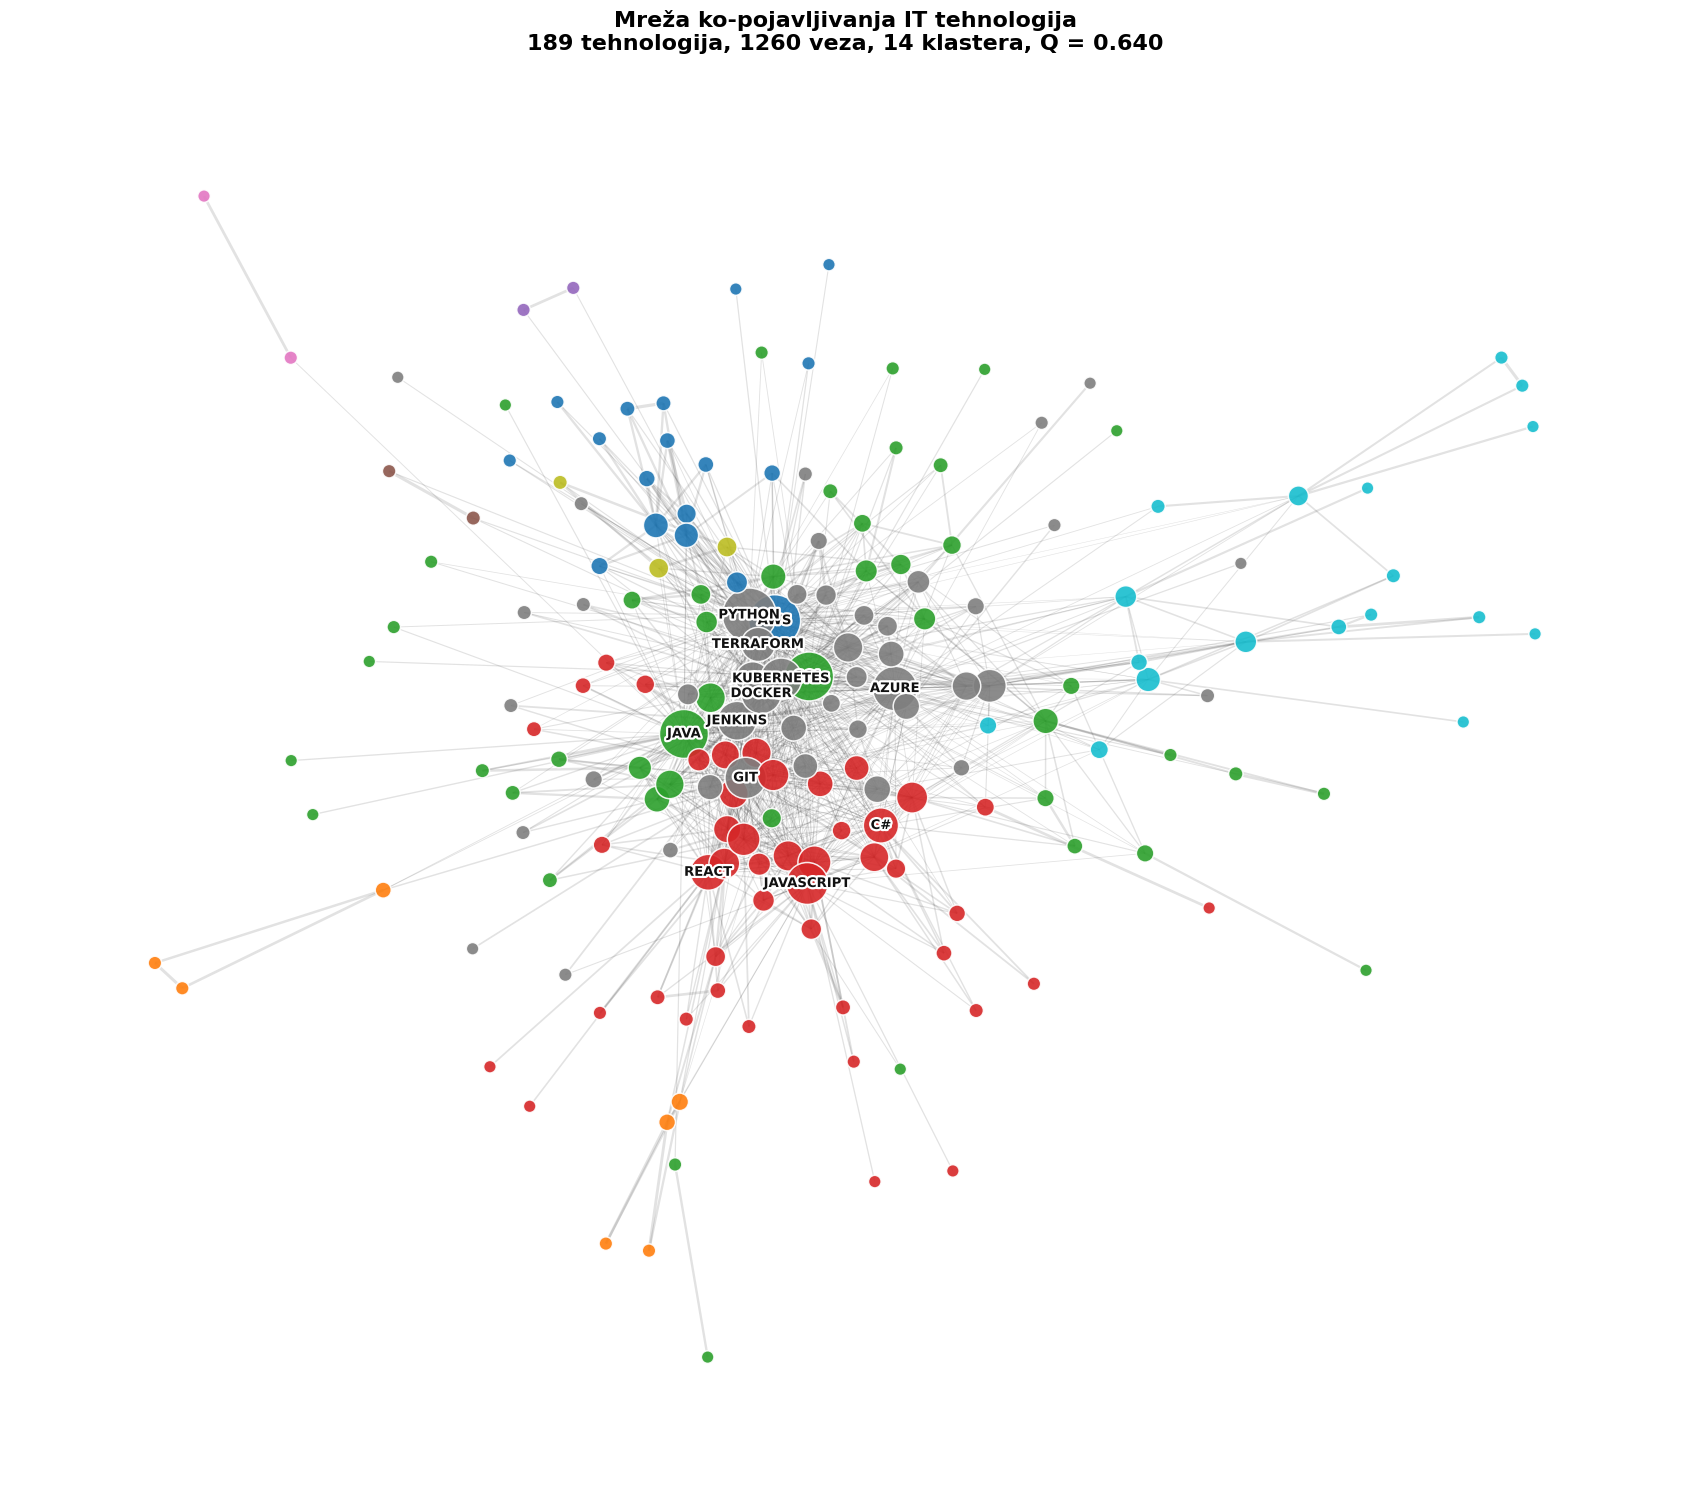

labela prikazano: 14 od 187


In [20]:
import numpy as np
import matplotlib.patheffects as pe

# Bela kontura oko teksta, jer se u gustom centru labele preklapaju,
# pa bez nje gornja postaje nečitljiva preko donje.
HALO = [pe.withStroke(linewidth=3.2, foreground="white")]

# log1p sabija opseg lifta (0,37-165) na (0,32-5,11) za prikaz i raspored
for u, v in G.edges():
    G[u][v]["prikaz"] = float(np.log1p(G[u][v]["weight"]))

komponente = sorted(nx.connected_components(G), key=len, reverse=True)
Gmain = G.subgraph(komponente[0]).copy()
sateliti = [sorted(k, key=lambda t: -frekvencija[t]) for k in komponente[1:]]

print(f"komponenti: {len(komponente)} | gigantska: {len(komponente[0])} čvorova")
for s in sateliti:
    print(f"   odvojeno: {', '.join(s)}")

pos = nx.spring_layout(Gmain, k=0.52, iterations=400, seed=42, weight="prikaz")

fig, ax = plt.subplots(figsize=(17, 15))
nx.draw_networkx_edges(
    Gmain, pos, ax=ax, alpha=0.14, edge_color="#333333",
    width=[0.18 + 0.42 * Gmain[u][v]["prikaz"] for u, v in Gmain.edges()],
)
nx.draw_networkx_nodes(
    Gmain, pos, ax=ax,
    node_size=[70 + 2400 * degree_c[n] for n in Gmain],
    node_color=[boja(n) for n in Gmain],
    alpha=0.9, edgecolors="white", linewidths=1.1,
)
# Samo 14 najpovezanijih. Centar grafa je pregust: sa 25+ labela se
# ORACLE i SQL SERVER stapaju u nečitljivo. Cela mreža služi za strukturu
# (boja = klaster, veličina = centralnost); imena se čitaju na slici top 50.
prag_labele = sorted((degree_c[n] for n in Gmain), reverse=True)[13]
vidljive = {n: n for n in Gmain if degree_c[n] >= prag_labele}
oznake = nx.draw_networkx_labels(Gmain, pos, labels=vidljive, ax=ax,
                                 font_size=9.5, font_weight="bold", font_color="#111111")
for t in oznake.values():
    t.set_path_effects(HALO)

ax.set_title(f"Mreža ko-pojavljivanja IT tehnologija\n"
             f"{G.number_of_nodes()} tehnologija, {G.number_of_edges()} veza, "
             f"{len(zajednice)} klastera, Q = {Q:.3f}",
             fontsize=16, fontweight="bold", pad=18)
ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "mreza_cela.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"labela prikazano: {len(vidljive)} od {Gmain.number_of_nodes()}")

### 6.2 Top 50 najčešćih tehnologija

Cela mreža pokazuje strukturu, ali se imena ne mogu čitati. Podgraf od 50
najčešćih tehnologija prikazuje sve labele.

Zajednice se računaju ponovo, nad podgrafom. Kada se uklone retke tehnologije,
preostale se drugačije grupišu, pa bi preuzimanje starih oznaka prikazalo podelu
koja za ovaj graf ne važi.

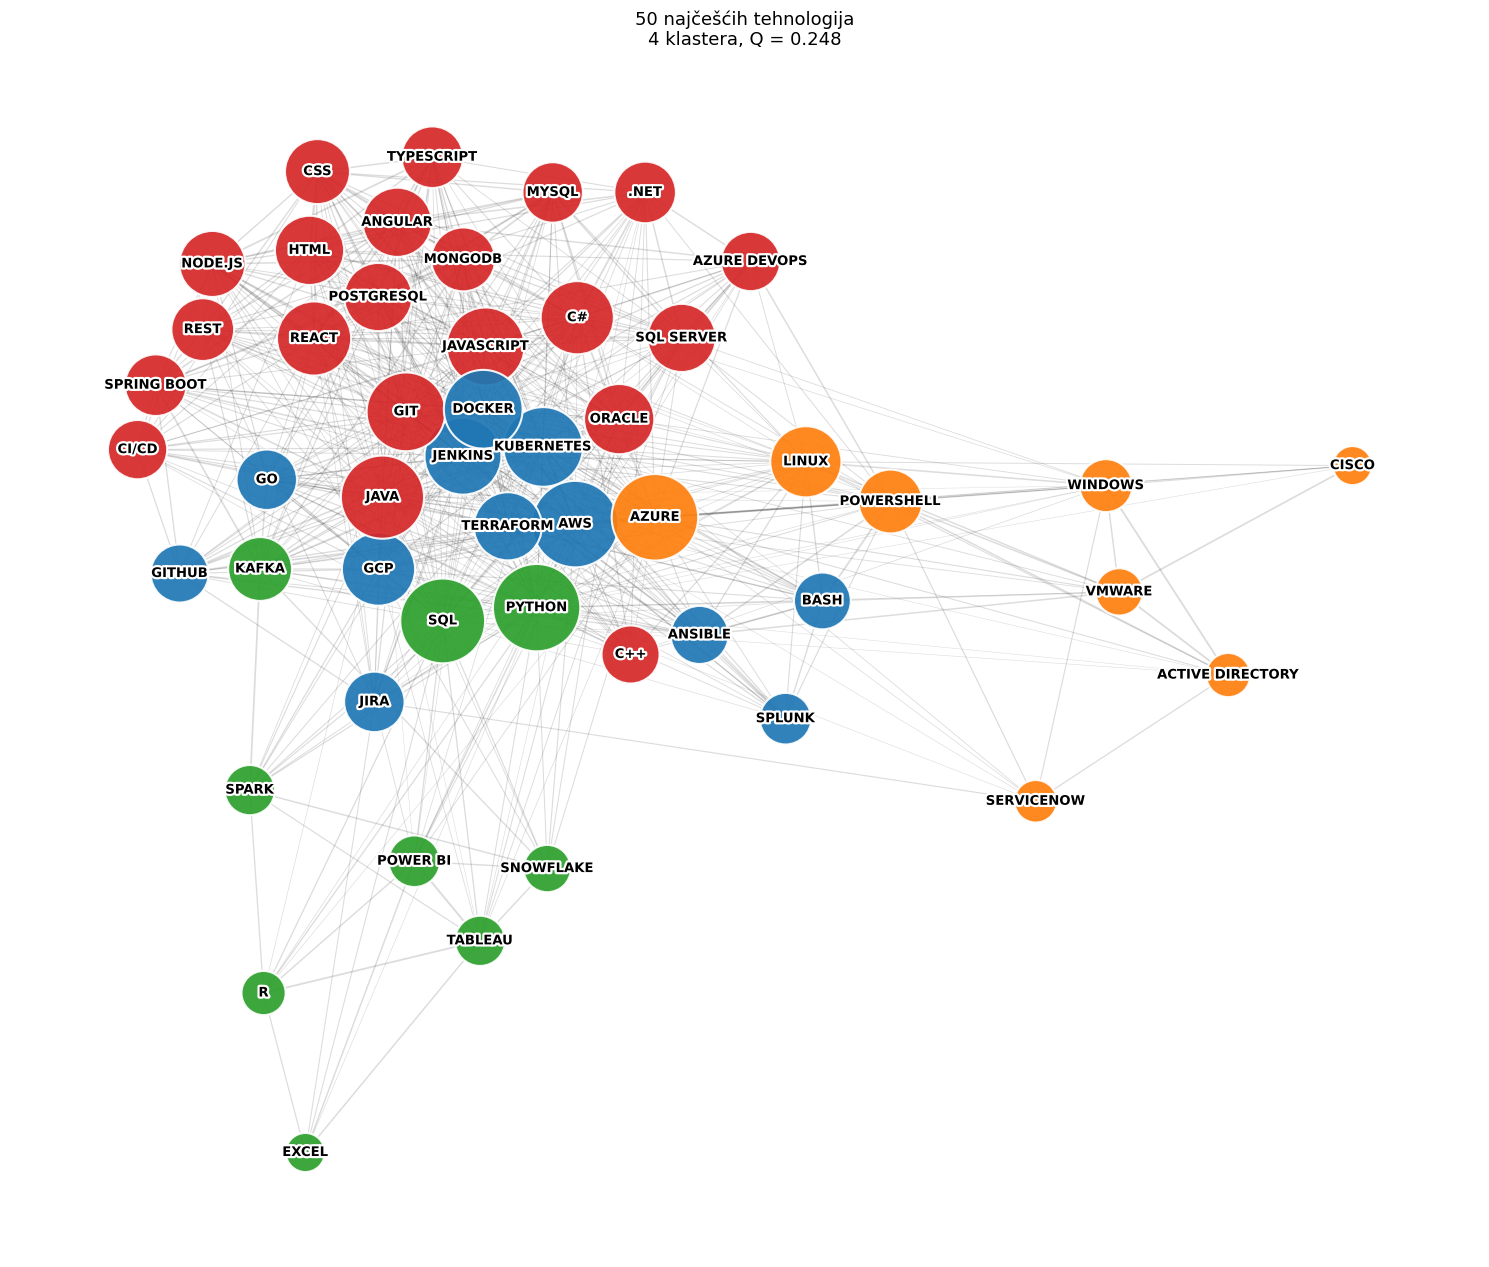

1. (21) JAVA / JAVASCRIPT / GIT / C#
2. (12) AWS / KUBERNETES / DOCKER / GCP
3. ( 9) PYTHON / SQL / POWER BI / TABLEAU
4. ( 8) AZURE / LINUX / WINDOWS / POWERSHELL


In [21]:
top50 = sorted(G.nodes, key=lambda n: (-frekvencija[n], n))[:50]
G50 = G.subgraph(top50).copy()

zajednice50 = tipicna_podela(G50, PONAVLJANJA_LOUVAIN)[0]
part50 = {n: i for i, z in enumerate(zajednice50) for n in z}
deg50 = nx.degree_centrality(G50)

pos50 = nx.spring_layout(G50, k=1.15, iterations=350, seed=42, weight="prikaz")

fig, ax = plt.subplots(figsize=(15, 13))
nx.draw_networkx_edges(G50, pos50, ax=ax, alpha=0.17, edge_color="#333333",
                       width=[0.2 + 0.5 * G50[u][v]["prikaz"] for u, v in G50.edges()])
nx.draw_networkx_nodes(G50, pos50, ax=ax,
                       node_size=[350 + 3600 * deg50[n] for n in G50],
                       node_color=[BOJE[part50[n] % len(BOJE)] for n in G50],
                       alpha=0.92, edgecolors="white", linewidths=1.5)
oznake50 = nx.draw_networkx_labels(G50, pos50, ax=ax, font_size=9.5, font_weight="bold")
for t in oznake50.values():
    t.set_path_effects(HALO)

ax.set_title(f"50 najčešćih tehnologija\n{len(zajednice50)} klastera, "
             f"Q = {nx.community.modularity(G50, zajednice50):.3f}",
             fontsize=16, fontweight="bold", pad=18)
ax.axis("off")
plt.tight_layout()
# u radu naslov stoji u natpisu ispod slike, pa se slika snima bez njega
_naslovi = {mesto: ax.get_title(loc=mesto) for mesto in ("left", "center", "right")}
for _mesto in _naslovi:
    ax.set_title("", loc=_mesto)
plt.savefig(FIG / "mreza_top50.png", dpi=200, bbox_inches="tight")
for _mesto, _tekst in _naslovi.items():
    ax.set_title(_tekst, loc=_mesto)
plt.show()

for i, z in enumerate(sorted(zajednice50, key=len, reverse=True), 1):
    print(f"{i}. ({len(z):2}) {potpis(z, 4)}")

### 6.3 Klasteri pojedinačno

Šest najvećih klastera, svaki zasebno. Raspored je Kamada-Kawai umesto spring
layout-a, jer minimizuje razliku između rastojanja na slici i rastojanja u grafu,
što na malim grafovima, do tridesetak čvorova, daje čitljiviju sliku. Na velikom
grafu bi bio prespor, pošto mu je složenost kvadratna.

Veličina čvora je ovde frekvencija u oglasima, a ne centralnost, jer je unutar
jednog klastera zanimljivije koja je tehnologija najtraženija.

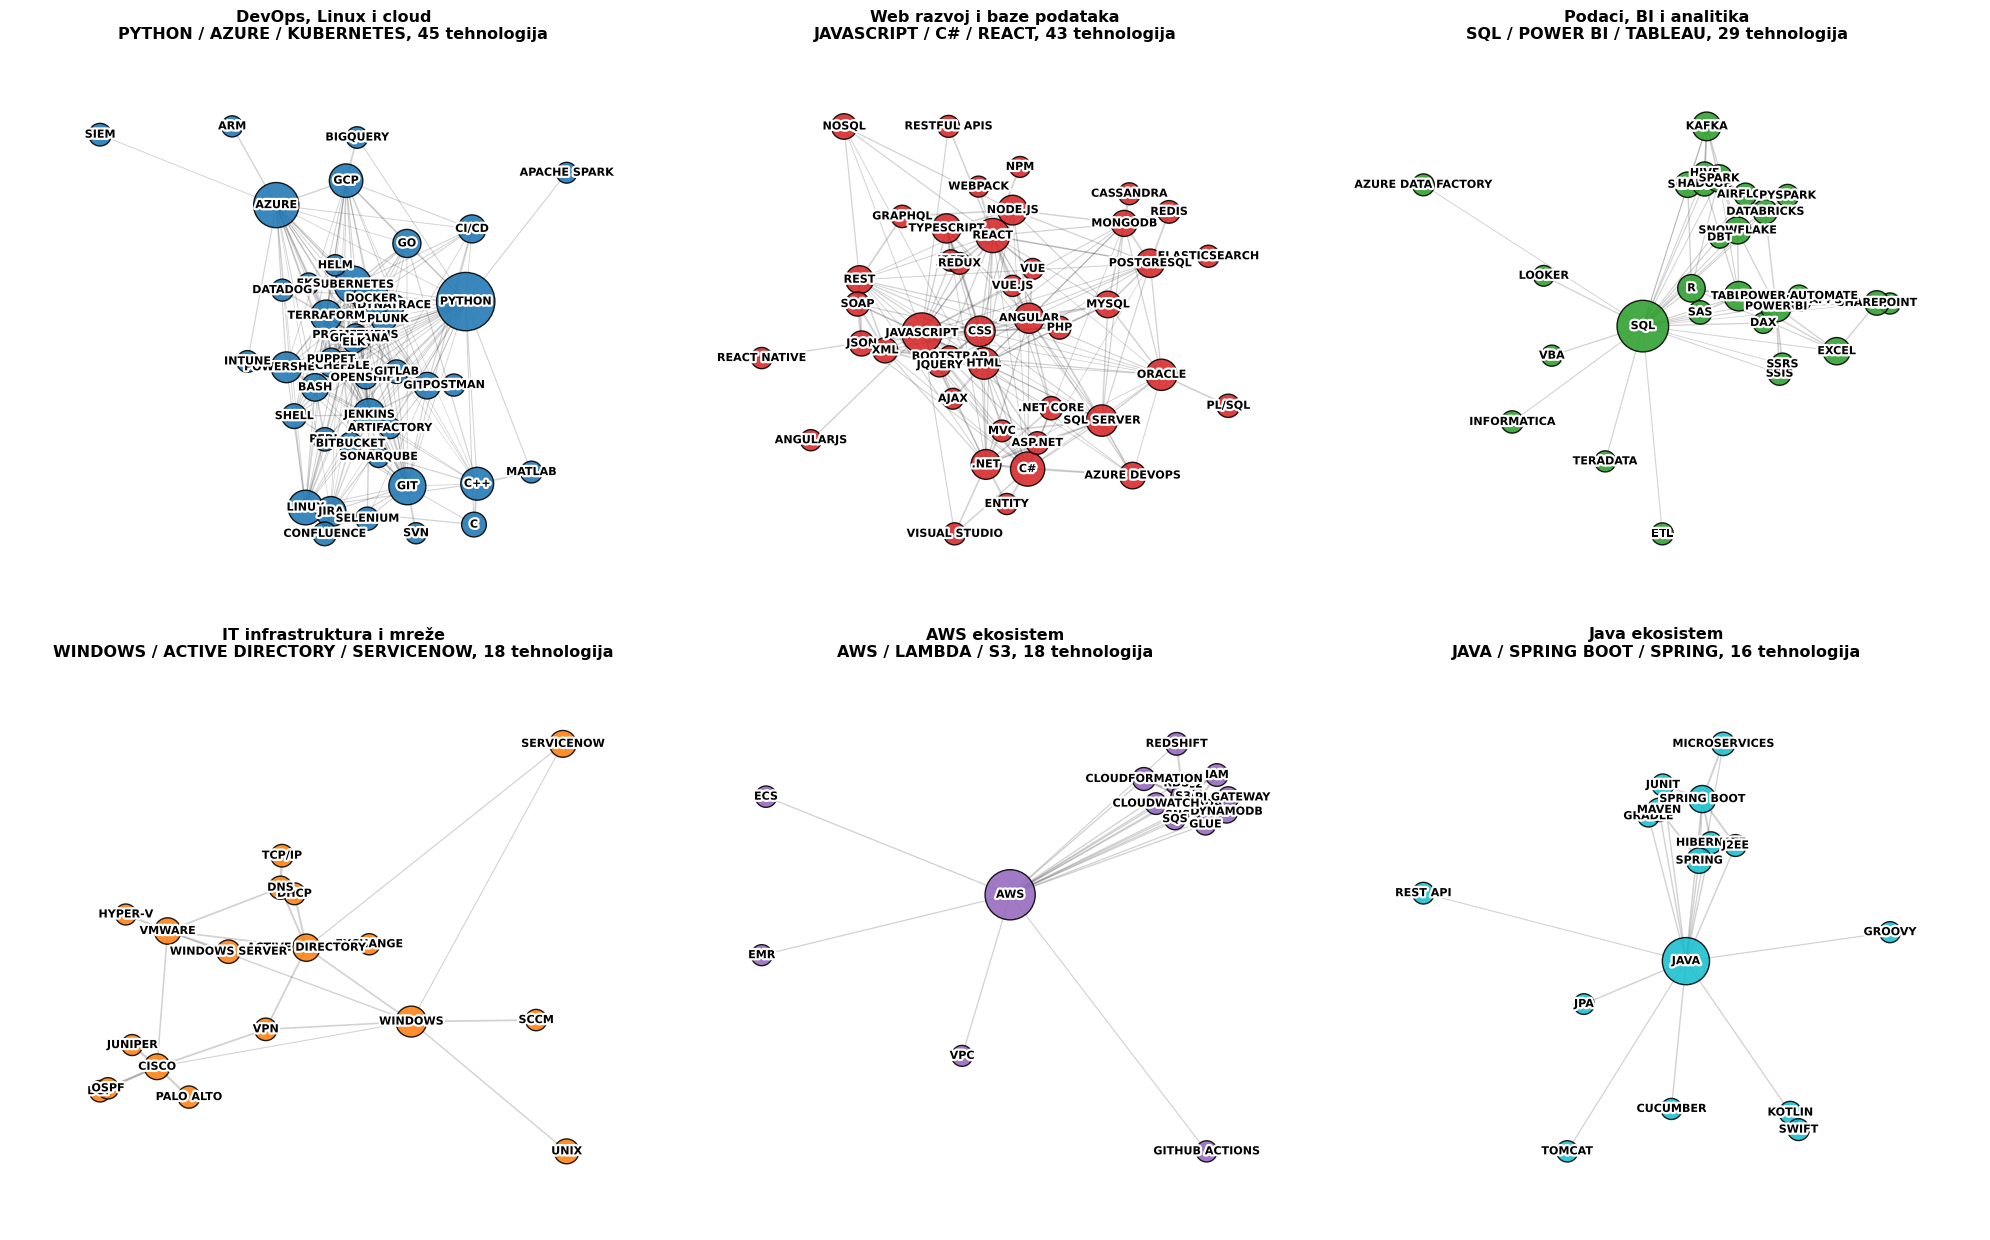

In [22]:
najveci = sorted(zajednice, key=len, reverse=True)[:6]

fig, axes = plt.subplots(2, 3, figsize=(20, 12.5))

for idx, (clanovi, ax) in enumerate(zip(najveci, axes.flat)):
    Gk = G.subgraph(clanovi).copy()
    posk = nx.kamada_kawai_layout(Gk, weight="rastojanje")

    nx.draw_networkx_edges(Gk, posk, ax=ax, alpha=0.22, edge_color="#333333",
                           width=[0.2 + 0.45 * Gk[u][v]["prikaz"] for u, v in Gk.edges()])
    nx.draw_networkx_nodes(Gk, posk, ax=ax,
                           node_size=[200 + 0.5 * frekvencija[n] for n in Gk],
                           node_color=BOJE[idx % len(BOJE)],
                           alpha=0.88, edgecolors="black", linewidths=1.0)
    oznakek = nx.draw_networkx_labels(Gk, posk, ax=ax, font_size=8, font_weight="bold")
    for t in oznakek.values():
        t.set_path_effects(HALO)

    ax.set_title(f"{ime_klastera(clanovi)}\n"
                 f"{potpis(clanovi)}, {len(clanovi)} tehnologija",
                 fontsize=11.5, fontweight="bold")
    ax.margins(0.13)
    ax.axis("off")

for ax in axes.flat[len(najveci):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIG / "mreza_klasteri.png", dpi=200, bbox_inches="tight")
plt.show()

In [23]:
# Zasebna slika svakog od šest najvećih klastera, sa krupnijim nazivima.
# Na širini strane u radu nazivi sa zbirne slike iznad bili bi oko 2 tačke.
putanje = []
for idx, clanovi in enumerate(najveci):
    Gk = G.subgraph(clanovi).copy()
    posk = nx.kamada_kawai_layout(Gk, weight="rastojanje")

    fig_k, ax_k = plt.subplots(figsize=(9, 6.5))
    nx.draw_networkx_edges(Gk, posk, ax=ax_k, alpha=0.22, edge_color="#333333",
                           width=[0.3 + 0.7 * Gk[u][v]["prikaz"] for u, v in Gk.edges()])
    nx.draw_networkx_nodes(Gk, posk, ax=ax_k,
                           node_size=[300 + 0.8 * frekvencija[n] for n in Gk],
                           node_color=BOJE[idx % len(BOJE)],
                           alpha=0.88, edgecolors="black", linewidths=1.0)
    for t in nx.draw_networkx_labels(Gk, posk, ax=ax_k, font_size=13, font_weight="bold").values():
        t.set_path_effects(HALO)
    ax_k.margins(0.15)
    ax_k.axis("off")

    naziv = re.sub(r"[^\w]+", "_", ime_klastera(clanovi).lower()).strip("_")
    putanja = FIG / f"klaster_{naziv}.png"
    fig_k.savefig(putanja, dpi=200, bbox_inches="tight")
    plt.close(fig_k)
    putanje.append(putanja.name)

print("sačuvano:", ", ".join(putanje))

sačuvano: klaster_devops_linux_i_cloud.png, klaster_web_razvoj_i_baze_podataka.png, klaster_podaci_bi_i_analitika.png, klaster_it_infrastruktura_i_mreže.png, klaster_aws_ekosistem.png, klaster_java_ekosistem.png


## 7. Mostovi između oblasti

Podgraf tehnologija sa visokim posredništvom, onih koje spajaju različite delove
mreže.

Prag `betweenness > 0.02` znači da tehnologija leži na više od 2 % svih najkraćih
puteva u mreži. Za razliku od pragova frekvencije, ovaj ne mora da bude relativan,
jer je betweenness već normalizovan kao udeo puteva, pa je uporediv bez obzira na
veličinu grafa.

Veličina čvora je ovde betweenness, a ne degree. Pitanje nije ko ima najviše veza
nego ko drži mrežu na okupu.

tehnologija sa betweenness > 0.02: 13 (od 189)


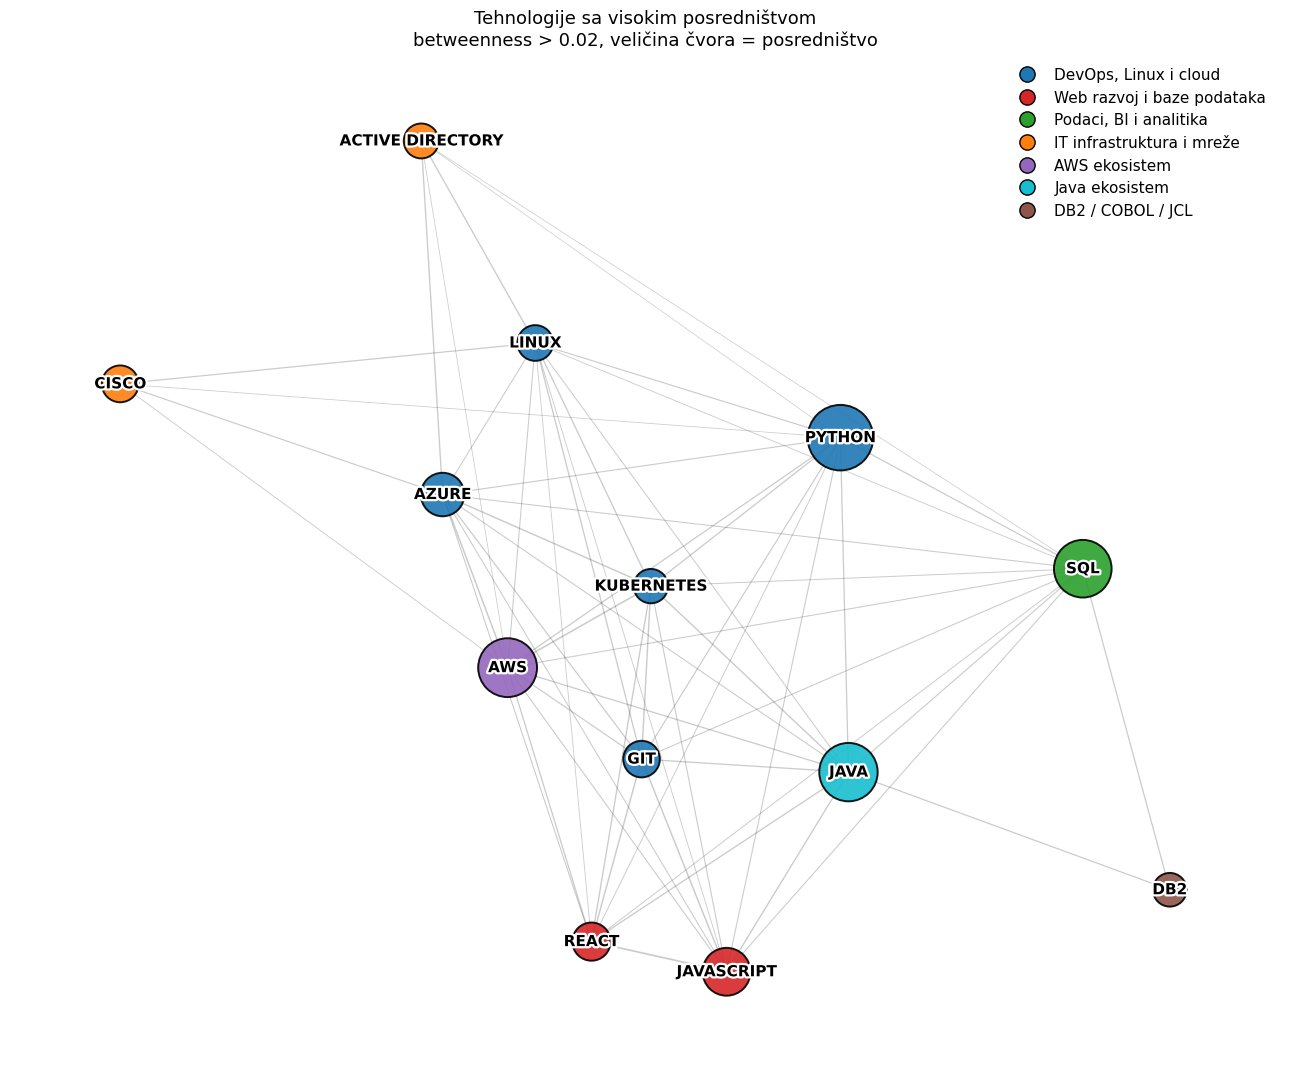

   PYTHON               betweenness 0.203, degree 0.601, DevOps, Linux i cloud
   AWS                  betweenness 0.155, degree 0.553, AWS ekosistem
   JAVA                 betweenness 0.152, degree 0.489, Java ekosistem
   SQL                  betweenness 0.147, degree 0.489, Podaci, BI i analitika
   JAVASCRIPT           betweenness 0.087, degree 0.351, Web razvoj i baze podataka
   AZURE                betweenness 0.065, degree 0.399, DevOps, Linux i cloud
   REACT                betweenness 0.040, degree 0.250, Web razvoj i baze podataka
   CISCO                betweenness 0.034, degree 0.059, IT infrastruktura i mreže
   GIT                  betweenness 0.033, degree 0.340, DevOps, Linux i cloud
   LINUX                betweenness 0.029, degree 0.207, DevOps, Linux i cloud
   ACTIVE DIRECTORY     betweenness 0.026, degree 0.074, IT infrastruktura i mreže
   KUBERNETES           betweenness 0.023, degree 0.340, DevOps, Linux i cloud
   DB2                  betweenness 0.021, degre

In [24]:
PRAG_MOSTA = 0.02

mostovi_cvorovi = [n for n in G if between_c[n] > PRAG_MOSTA]
Gm = G.subgraph(mostovi_cvorovi).copy()
print(f"tehnologija sa betweenness > {PRAG_MOSTA}: {Gm.number_of_nodes()} "
      f"(od {G.number_of_nodes()})")

posm = nx.kamada_kawai_layout(Gm, weight="rastojanje")
fig, ax = plt.subplots(figsize=(13, 11))

nx.draw_networkx_edges(Gm, posm, ax=ax, alpha=0.25, edge_color="#333333",
                       width=[0.3 + 0.6 * Gm[u][v]["prikaz"] for u, v in Gm.edges()])
# Na ovoj slici je sedam klastera, pa svaki dobija svoju boju; opšta funkcija boja()
# ima deset boja za 14 klastera i ovde bi SQL i Java dobili istu boju.
klasteri_m = sorted({partition[n] for n in Gm}, key=lambda k: -len(zajednice[k]))
boja_m = {k: BOJE[i] for i, k in enumerate(klasteri_m)}
nx.draw_networkx_nodes(Gm, posm, ax=ax,
                       node_size=[400 + 9000 * between_c[n] for n in Gm],
                       node_color=[boja_m[partition[n]] for n in Gm],
                       alpha=0.9, edgecolors="black", linewidths=1.4)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markersize=11, markerfacecolor=boja_m[k],
                          markeredgecolor="black", label=ime_klastera(zajednice[k])) for k in klasteri_m],
          loc="upper right", frameon=False, fontsize=11)
oznakem = nx.draw_networkx_labels(Gm, posm, ax=ax, font_size=11, font_weight="bold")
for t in oznakem.values():
    t.set_path_effects(HALO)

ax.set_title("Tehnologije sa visokim posredništvom\n"
             f"betweenness > {PRAG_MOSTA}, veličina čvora = posredništvo",
             fontsize=15, fontweight="bold", pad=16)
ax.axis("off")
plt.tight_layout()
# u radu naslov stoji u natpisu ispod slike, pa se slika snima bez njega
_naslovi = {mesto: ax.get_title(loc=mesto) for mesto in ("left", "center", "right")}
for _mesto in _naslovi:
    ax.set_title("", loc=_mesto)
plt.savefig(FIG / "mreza_mostovi.png", dpi=200, bbox_inches="tight")
for _mesto, _tekst in _naslovi.items():
    ax.set_title(_tekst, loc=_mesto)
plt.show()

for n in sorted(Gm, key=lambda x: -between_c[x]):
    print(f"   {n:20} betweenness {between_c[n]:.3f}, degree {degree_c[n]:.3f}, "
          f"{ime_klastera(zajednice[partition[n]])}")

### Provera: artikulacione tačke

Granica od 0,02 za posredništvo je izabrana, pa bi se spisak sa slike iznad
promenio kada bi se granica pomerila. Zato se spisak proverava merom koja ne
zahteva izbor granice: artikulaciona tačka (articulation point) je čvor čijim se
uklanjanjem graf raspada na više delova koji međusobno nisu povezani. Odgovor je
samo da ili ne.

Tehnologija koja je jedini prolaz ka nekom delu mreže mora biti artikulaciona
tačka, pa njeno uklanjanje mora nešto da odseče.

In [25]:
Ggl = G.subgraph(max(nx.connected_components(G), key=len)).copy()

tacke = []
for cvor in nx.articulation_points(Ggl):
    bez = Ggl.copy()
    bez.remove_node(cvor)
    odsecene = sorted(nx.connected_components(bez), key=len, reverse=True)[1:]
    tacke.append((cvor, sum(len(k) for k in odsecene), odsecene))

print(f"artikulacionih tačaka: {len(tacke)} od {Ggl.number_of_nodes()} čvorova\n")
for cvor, koliko, odsecene in sorted(tacke, key=lambda x: -x[1])[:8]:
    grupe = ", ".join(", ".join(sorted(k)) for k in odsecene)
    print(f"   {cvor:14} odseca {koliko:2}: {grupe}")

artikulacionih tačaka: 18 od 187 čvorova

   JAVA           odseca  8: OAUTH, SAML, KOTLIN, SWIFT, REST API, TOMCAT, CUCUMBER, JPA
   CISCO          odseca  3: BGP, OSPF, JUNIPER
   SQL            odseca  3: LOOKER, TERADATA, VBA
   PYTHON         odseca  3: DJANGO, FLASK, APACHE SPARK
   DB2            odseca  2: COBOL, JCL
   REACT          odseca  2: NPM, WEBPACK
   AWS            odseca  2: VPC, GITHUB ACTIONS
   JAVASCRIPT     odseca  2: REACT NATIVE, ANGULARJS


### Habovi i mostovi

Među 13 tehnologija sa visokim posredništvom razlikuju se dve grupe, i važne su
iz suprotnih razloga.

Habovi su `PYTHON`, `AWS`, `JAVA` i `SQL`. Visoki su i po degree i po
betweenness. Posrednici su zato što su povezani sa gotovo svim oblastima: Python
je u 26,7 % oglasa i povezan sa 113 tehnologija iz deset klastera.

Mostovi sa malo veza su `CISCO`, `ACTIVE DIRECTORY` i `DB2`. Degree im je pri
dnu, Cisco ima samo 11 veza, ali su posrednici zato što jednu usku oblast
povezuju sa ostatkom mreže. Cisco je artikulaciona tačka koja odseca `BGP`,
`OSPF` i `JUNIPER`, a DB2 sa pet veza drži `COBOL` i `JCL` vezane za ostatak
mreže.

Degree ovu drugu grupu ne vidi, zato se mere obe.

Hab vodi ka više oblasti odjednom. Most sa malo veza vodi ka jednoj uskoj oblasti,
pa je onaj ko se specijalizuje za BGP i OSPF sa ostatkom tržišta povezan
uglavnom preko Cisco-a.

Artikulacione tačke su činjenica o grafu pri pragu od 0,3 %, jer niži prag
dodaje ivice i neke od tih tačaka nestaju. Ćelija ispod računa brojeve iz ovog
dela.

In [26]:
# Brojevi iz rada, odeljak 5.3
tacke_skup = {cvor for cvor, _, _ in tacke}
print(f"od {len(mostovi_cvorovi)} tehnologija sa betweenness > {PRAG_MOSTA}, "
      f"artikulacione tačke su {len(tacke_skup & set(mostovi_cvorovi))}")
print("   nisu:", ", ".join(sorted(set(mostovi_cvorovi) - tacke_skup)))

print("\nbroj veza i koliko tehnologija u mreži ima više veza:")
for t in ["CISCO", "ACTIVE DIRECTORY", "DB2", "PYTHON", "JAVA"]:
    print(f"   {t:17} {G.degree(t):4} veza, više ima {sum(G.degree(n) > G.degree(t) for n in G):3} tehnologija")
print(f"\nPYTHON je povezan sa tehnologijama iz {len({partition[n] for n in G['PYTHON']})} klastera")

# isti graf pri nižem pragu od 0,2 %
G2 = gradi_graf(0.002, 0.002)
G2gl = G2.subgraph(max(nx.connected_components(G2), key=len))
nestaju = tacke_skup - set(nx.articulation_points(G2gl))
print(f"\npri pragu od 0,2 % prestaje da bude artikulaciona tačka {len(nestaju)} od {len(tacke_skup)}: "
      + ", ".join(sorted(nestaju)))

od 13 tehnologija sa betweenness > 0.02, artikulacione tačke su 11
   nisu: KUBERNETES, LINUX

broj veza i koliko tehnologija u mreži ima više veza:
   CISCO               11 veza, više ima  60 tehnologija
   ACTIVE DIRECTORY    14 veza, više ima  50 tehnologija
   DB2                  5 veza, više ima  98 tehnologija
   PYTHON             113 veza, više ima   0 tehnologija
   JAVA                92 veza, više ima   2 tehnologija

PYTHON je povezan sa tehnologijama iz 10 klastera

pri pragu od 0,2 % prestaje da bude artikulaciona tačka 7 od 18: DB2, GIT, KOTLIN, RUBY, SPLUNK, SQL, VMWARE


## 8. Interaktivna vizualizacija

Statične slike pokazuju strukturu, ali se pojedinačan čvor ne može ispitati.
PyVis pravi HTML stranicu sa zumiranjem i podacima o čvoru u tooltipu.

Fizika je `forceAtlas2Based`, isti princip kao `spring_layout`, uz simulaciju
koja se izvršava u pregledaču.

Dva detalja u kodu:

- debljina ivice ide preko `log1p(lift)`, jer bi sirov lift dao linije od
  nekoliko desetina piksela
- grafu se prosleđuje kopija, pošto `net.from_nx()` menja prosleđeni graf u mestu
  i preimenuje atribut `weight` u `width`. Bez kopije bi `G` ostao bez težina, pa
  bi i `graf.graphml` i svako naredno računanje centralnosti radili nad
  osakaćenim grafom

In [27]:
from pyvis.network import Network

net = Network(height="900px", width="100%", bgcolor="#111418",
              font_color="#E8ECF0", notebook=False, cdn_resources="in_line")
net.from_nx(G.copy())   # kopija: from_nx menja graf u mestu (weight -> width)

PALETA = ["#4C9BE8", "#E8595F", "#3FBF87", "#F0913C", "#A97BE0",
          "#3FC4C4", "#B0764F", "#E07FC0", "#8E99A6", "#C9C24A"]

for cvor in net.nodes:
    ime = cvor["id"]
    k = partition[ime]
    cvor["color"] = PALETA[k % len(PALETA)]
    cvor["size"] = 8 + 55 * degree_c[ime]
    cvor["label"] = ime
    cvor["font"] = {"size": 13, "color": "#E8ECF0"}
    cvor["title"] = (
        f"{ime}\n"
        f"klaster: {ime_klastera(zajednice[k])}\n"
        f"oglasa: {frekvencija[ime]}\n"
        f"degree: {degree_c[ime]:.3f}\n"
        f"betweenness: {between_c[ime]:.3f}"
    )

for ivica in net.edges:              # jedna petlja, ne ugnježdena kao ranije
    veza = G[ivica["from"]][ivica["to"]]
    ivica["width"] = 0.4 + 1.1 * veza["prikaz"]
    ivica["color"] = {"color": "rgba(150,160,170,0.28)", "highlight": "#F0C040"}
    ivica["title"] = (f"lift {veza['weight']:.2f}, "
                      f"zajedno u {veza['support']} oglasa")

assert "weight" in next(iter(G.edges(data=True)))[2], "from_nx je pojeo težine"

net.set_options("""
{
  "physics": {
    "solver": "forceAtlas2Based",
    "forceAtlas2Based": {
      "gravitationalConstant": -60, "centralGravity": 0.012,
      "springLength": 190, "springConstant": 0.05, "avoidOverlap": 0.7
    },
    "maxVelocity": 45, "minVelocity": 0.6, "timestep": 0.35,
    "stabilization": {"iterations": 220}
  },
  "interaction": {"hover": true, "tooltipDelay": 120,
                  "navigationButtons": true, "keyboard": true}
}
""")

izlaz = FIG / "mreza_interaktivna.html"
net.write_html(str(izlaz), notebook=False)
print(f"sačuvano: {izlaz}  ({izlaz.stat().st_size/1024:.0f} KB)")


sačuvano: figures/mreza_interaktivna.html  (1103 KB)


## 9. Čuvanje grafa

Graf i podela na klastere se upisuju na disk, da bi `03_preporuka.ipynb` mogao da
ih koristi bez ponovnog računanja.

Uz graf se čuva i rečnik kanonskih naziva, jer bez njega rezultati preporuke ne
bi bili uporedivi sa mrežom. Pravilo `{REACT} -> {TYPESCRIPT}` ima smisla samo ako
su nazivi normalizovani na isti način.

Umesto `pickle`, koriste se GraphML za graf i JSON za ostalo. Pickle je vezan za
verziju biblioteke i nije čitljiv van Pythona, dok se GraphML otvara i u Gephi-ju
ako zatreba drugačija vizualizacija.

In [28]:
import json

nx.set_node_attributes(G, {n: ime_klastera(zajednice[partition[n]]) for n in G}, "ime_klastera")
nx.write_graphml(G, INTERIM / "graf.graphml")

meta = {
    "broj_oglasa": int(N),
    "prag_cvora": PRAG_CVORA,
    "prag_ivice": PRAG_IVICE,
    "modularnost": round(float(Q), 4),
    "partition": {n: int(partition[n]) for n in G},
    "louvain_pokretanja": PONAVLJANJA_LOUVAIN,
    "stabilnost_clanova": {n: round(stabilnost_clanova.get(n, 1.0), 3) for n in G},
    "imena_klastera": {str(i): ime_klastera(z) for i, z in enumerate(zajednice)},
    "frekvencija": {n: int(frekvencija[n]) for n in G},
    "sinonimi": SINONIMI,
    "nije_tehnologija": sorted(NIJE_TEHNOLOGIJA),
    "rastavi": RASTAVI,
}
(INTERIM / "graf_meta.json").write_text(
    json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")

dataset.to_parquet(INTERIM / "dataset_kanonizovan.parquet", index=False)

for p in ["graf.graphml", "graf_meta.json", "dataset_kanonizovan.parquet"]:
    print(f"   {p:32} {(INTERIM / p).stat().st_size/1024:8.0f} KB")

   graf.graphml                          341 KB
   graf_meta.json                         12 KB
   dataset_kanonizovan.parquet          1213 KB


## 10. Metrike za korelacionu analizu

Odavde počinje korelaciona analiza iz projekta: mrežna analiza daje strukturu, a
ovaj deo traži brojeve po oglasu.

| metrika | šta meri |
|---|---|
| `num_skills` | koliko tehnologija oglas traži |
| `num_klastera` | koliko različitih oblasti te tehnologije pokrivaju |
| `pokrivenost` | udeo tehnologija oglasa koje uopšte postoje u grafu |
| `diversity_ratio` | `num_klastera / num_skills`, širina po jedinici znanja |
| `net_flags` | `green − red` |
| `conversion_rate` | `applies / views` |

Tehnologije i podela na klastere dolaze iz iste funkcije `canonicalize()` koja je
korišćena pri gradnji mreže, pa se nazivi u tabeli i ključevi podele poklapaju.

### Nula klastera nije isto što i netehnički oglas

Oglas može imati nula klastera iz dva razloga, a samo prvi znači da oglas nije
tehnički:

1. nema nijednu tehnologiju, model nije našao ništa
2. ima tehnologije, ali nijedna nije u grafu, na primer `SAP`, `PLC` ili
   `AUTOCAD`; to su stvarne tehnologije, samo ne dovoljno česte da pređu prag

Zato postoji kolona `grupa_pokrivenosti`, da se u korelacionoj analizi ove
populacije mogu razdvojiti umesto da se sve zovu nulom.

In [29]:
it = dataset[dataset["is_it_role"]].copy()

it["num_skills"] = it["tech"].apply(len)
it["tech_u_grafu"] = it["tech"].apply(lambda l: [t for t in l if t in partition])
it["num_u_grafu"] = it["tech_u_grafu"].apply(len)
it["num_klastera"] = it["tech_u_grafu"].apply(lambda l: len({partition[t] for t in l}))

it["pokrivenost"] = np.where(it["num_skills"] > 0,
                             it["num_u_grafu"] / it["num_skills"].replace(0, np.nan), np.nan)
it["diversity_ratio"] = np.where(it["num_skills"] > 0,
                                 it["num_klastera"] / it["num_skills"].replace(0, np.nan), np.nan)

it["grupa_pokrivenosti"] = np.select(
    [it["num_skills"] == 0, it["num_u_grafu"] == 0],
    ["bez tehnologija", "tehnologije van grafa"],
    default="u grafu")

print("Raspodela num_klastera:")
print(it["num_klastera"].value_counts().sort_index().to_string())

nula = it[it["num_klastera"] == 0]
print(f"\nOglasa sa 0 klastera: {len(nula):,} ({len(nula)/len(it)*100:.1f}%)")
print(nula["grupa_pokrivenosti"].value_counts().to_string())

print(f"\nPokrivenost među oglasima koji imaju tehnologije:")
print(f"   prosek {it['pokrivenost'].mean()*100:.1f}%  medijana {it['pokrivenost'].median()*100:.1f}%")
print("   -> num_klastera se računa u proseku nad dve trećine navedenih tehnologija")

Raspodela num_klastera:
num_klastera
0    2093
1    2785
2    2969
3    2154
4    1211
5     437
6      58
7       6

Oglasa sa 0 klastera: 2,093 (17.9%)
grupa_pokrivenosti
bez tehnologija          1080
tehnologije van grafa    1013

Pokrivenost među oglasima koji imaju tehnologije:
   prosek 62.0%  medijana 66.7%
   -> num_klastera se računa u proseku nad dve trećine navedenih tehnologija


### Zastavice i seniority

In [30]:
it["num_red"] = it["red_flags"].apply(len)
it["num_green"] = it["green_flags"].apply(len)
it["net_flags"] = it["num_green"] - it["num_red"]

REDOSLED_SENIORITY = ["Internship", "Entry level", "Associate",
                      "Mid-Senior level", "Director", "Executive"]
it["seniority"] = pd.Categorical(it["formatted_experience_level"],
                                 categories=REDOSLED_SENIORITY, ordered=True)

print(it[["num_skills", "num_klastera", "diversity_ratio",
          "num_red", "num_green", "net_flags", "vibe_score"]].describe().round(2).to_string())
print(f"\nseniority (iz postings.csv, bez LLM-a):")
print(it["seniority"].value_counts().reindex(REDOSLED_SENIORITY).to_string())
print(f"   nedostaje: {it['seniority'].isna().sum():,}")

       num_skills  num_klastera  diversity_ratio   num_red  num_green  net_flags  vibe_score
count    11713.00      11713.00         10633.00  11713.00   11713.00   11713.00    11713.00
mean         7.14          1.93             0.34      0.29       2.08       1.79        5.73
std          5.77          1.40             0.24      0.71       3.52       3.58        1.20
min          0.00          0.00             0.00      0.00       0.00      -6.00        2.00
25%          3.00          1.00             0.18      0.00       0.00       0.00        5.00
50%          6.00          2.00             0.29      0.00       0.00       0.00        5.00
75%         10.00          3.00             0.45      0.00       4.00       3.00        7.00
max         52.00          7.00             1.00      7.00      28.00      28.00        9.00

seniority (iz postings.csv, bez LLM-a):
seniority
Internship            81
Entry level         1915
Associate            713
Mid-Senior level    5515
Director    

### `conversion_rate` i zašto mu treba prag

`applies / views` je mera angažovanja kandidata. Bez ograničenja, oglas sa 7
pregleda i 2 prijave daje 0,29, jednako kao oglas sa 700 pregleda i 200 prijava.

Problem nije samo šum nego i granularnost: pri 7 pregleda razmera može da uzme
samo vrednosti 0, 0,14, 0,29 i tako redom, pa se fina razlika ne može ni izraziti.
Medijana `views` među oglasima koji taj podatak uopšte imaju je 7, a donjih 10 %
ima 2 ili manje.

Prag je 20 pregleda, jer je tada najmanji korak 5 %. Osetljivost na izbor praga
je prikazana ispod, da izbor ne bude proizvoljan.

In [31]:
MIN_VIEWS = 20

ima_oboje = it["views"].notna() & it["applies"].notna()
it["conversion_rate"] = np.where(ima_oboje & (it["views"] >= MIN_VIEWS),
                                 it["applies"] / it["views"].replace(0, np.nan), np.nan)

print("Osetljivost na prag:")
for prag in [0, 10, 20, 50, 100]:
    pod = it[ima_oboje & (it["views"] >= prag)]
    cr = pod["applies"] / pod["views"]
    print(f"   views >= {prag:3}:  n = {len(pod):5}   medijana CR = {cr.median():.3f}   "
          f"najmanji korak = {1/prag*100 if prag else float('inf'):.1f}%")

print(f"\nizabrano: views >= {MIN_VIEWS} -> {it['conversion_rate'].notna().sum():,} oglasa")
assert (it["conversion_rate"].dropna() <= 1).all(), "conversion_rate > 1, applies veći od views"

dataset_metrike = it
dataset_metrike.to_parquet(INTERIM / "dataset_metrike.parquet", index=False)
print(f"upisano: dataset_metrike.parquet ({len(dataset_metrike):,} redova, "
      f"{len(dataset_metrike.columns)} kolona)")

Osetljivost na prag:
   views >=   0:  n =  5118   medijana CR = 0.222   najmanji korak = inf%
   views >=  10:  n =  4233   medijana CR = 0.222   najmanji korak = 10.0%
   views >=  20:  n =  3194   medijana CR = 0.243   najmanji korak = 5.0%
   views >=  50:  n =  1747   medijana CR = 0.283   najmanji korak = 2.0%
   views >= 100:  n =   860   medijana CR = 0.325   najmanji korak = 1.0%

izabrano: views >= 20 -> 3,194 oglasa


upisano: dataset_metrike.parquet (11,713 redova, 30 kolona)


## 11. Širina znanja i plata

Istraživačko pitanje: da li poznavanje više različitih tehnoloških oblasti donosi
višu platu?

Širina je `num_klastera`, broj različitih oblasti iz mreže koje oglas pokriva.
Račun se radi nad svim oglasima sa platom u opsegu, pa zatim još jednom bez
grupe sa nula klastera, pošto ta grupa meša oglase bez tehnologija sa oglasima
čije tehnologije nisu prešle prag.

Uz Pearsonov `r` ide i Spearmanov ρ, jer su plate desno iskošene, a Pearson meri
isključivo linearnu vezu i osetljiv je na ekstreme. Uz svaki koeficijent ide i
p-vrednost.

In [32]:
sa_platom = dataset_metrike[
    dataset_metrike["godisnja_plata"].between(20_000, 500_000)].copy()

print(f"oglasa sa validnom godišnjom platom: {len(sa_platom):,}")
print(f"medijana: ${sa_platom['godisnja_plata'].median():,.0f}\n")


def korelacija(x, y, opis):
    m = x.notna() & y.notna()
    r, p_r = stats.pearsonr(x[m], y[m])
    rho, p_rho = stats.spearmanr(x[m], y[m])
    print(f"{opis:38} n={m.sum():5}   r = {r:+.4f} (p={p_r:.4f})   "
          f"ρ = {rho:+.4f} (p={p_rho:.4f})")
    return r


bez_nula = sa_platom[sa_platom["num_klastera"] > 0]

print("               ŠIRINA ZNANJA vs PLATA")
r_svi   = korelacija(sa_platom["num_klastera"], sa_platom["godisnja_plata"], "svi oglasi")
r_bez   = korelacija(bez_nula["num_klastera"], bez_nula["godisnja_plata"], "bez grupe sa 0 klastera")
r_broj  = korelacija(sa_platom["num_skills"], sa_platom["godisnja_plata"], "broj tehnologija (količina)")
r_ratio = korelacija(sa_platom["diversity_ratio"], sa_platom["godisnja_plata"], "diversity_ratio")



oglasa sa validnom godišnjom platom: 3,411
medijana: $131,600

               ŠIRINA ZNANJA vs PLATA
svi oglasi                             n= 3411   r = +0.1063 (p=0.0000)   ρ = +0.1361 (p=0.0000)
bez grupe sa 0 klastera                n= 2789   r = +0.1050 (p=0.0000)   ρ = +0.1297 (p=0.0000)
broj tehnologija (količina)            n= 3411   r = +0.0423 (p=0.0134)   ρ = +0.0782 (p=0.0000)
diversity_ratio                        n= 3060   r = +0.0549 (p=0.0024)   ρ = +0.0737 (p=0.0000)


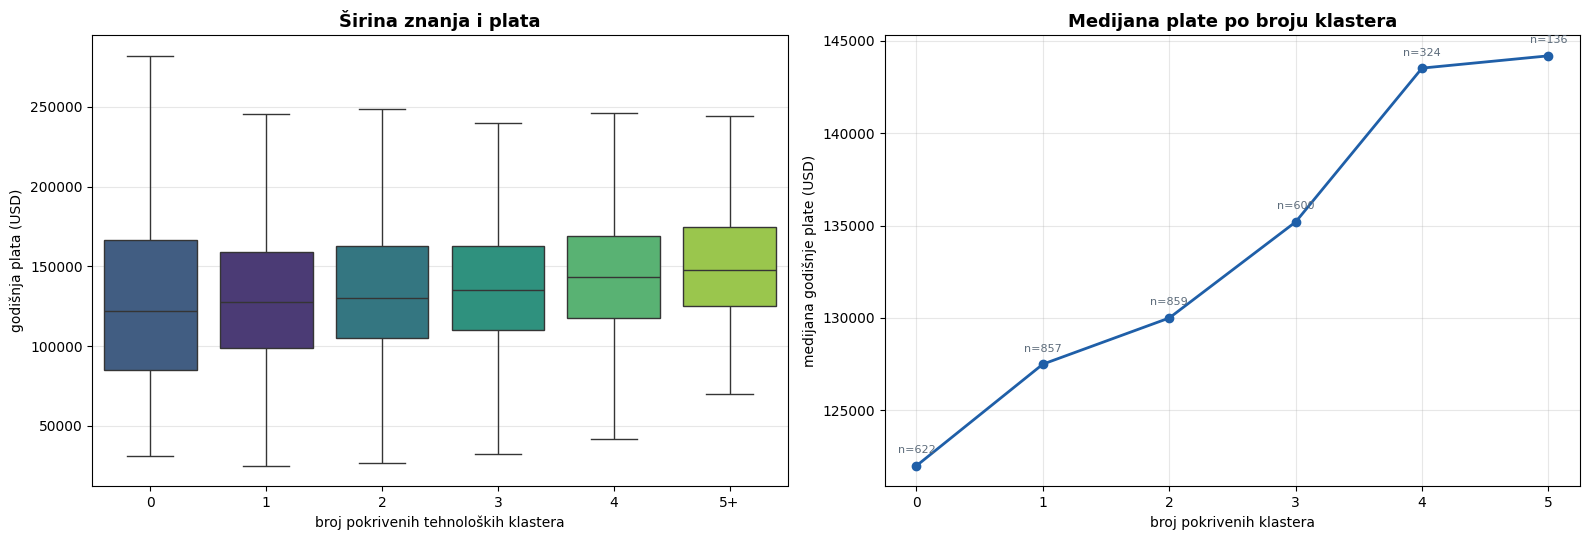

              count    median
num_klastera                 
0               622  122000.0
1               857  127500.0
2               859  130000.0
3               600  135200.0
4               324  143530.0
5               136  144195.0
6                10  146950.0
7                 3  181300.0


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

grupe = sa_platom.copy()
grupe["klasteri"] = grupe["num_klastera"].apply(lambda x: str(x) if x < 5 else "5+")
redosled = ["0", "1", "2", "3", "4", "5+"]

sns.boxplot(data=grupe, x="klasteri", y="godisnja_plata", order=redosled,
            hue="klasteri", palette="viridis", legend=False, ax=axes[0], showfliers=False)
axes[0].set_title("Širina znanja i plata", fontsize=13, fontweight="bold")
axes[0].set_xlabel("broj pokrivenih tehnoloških klastera")
axes[0].set_ylabel("godišnja plata (USD)")
axes[0].grid(axis="y", alpha=0.3)

medijane = sa_platom.groupby("num_klastera")["godisnja_plata"].agg(["median", "count"])
medijane = medijane[medijane["count"] >= 20]
axes[1].plot(medijane.index, medijane["median"], marker="o", linewidth=2, color="#1F5FA8")
for k, red in medijane.iterrows():
    axes[1].annotate(f"n={int(red['count'])}", (k, red["median"]),
                     textcoords="offset points", xytext=(0, 9),
                     ha="center", fontsize=8, color="#5C6B7A")
axes[1].set_title("Medijana plate po broju klastera", fontsize=13, fontweight="bold")
axes[1].set_xlabel("broj pokrivenih klastera")
axes[1].set_ylabel("medijana godišnje plate (USD)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG / "plata_sirina.png", dpi=200, bbox_inches="tight")
plt.show()

print(sa_platom.groupby("num_klastera")["godisnja_plata"]
      .agg(["count", "median"]).round(0).to_string())

## 12. Šta je zapravo grupa sa nula klastera

Grupa se razlaže po `grupa_pokrivenosti` i `role_family`, da se vidi da li je reč
o netehničkim oglasima ili o tehnologijama koje nisu prešle prag.

In [34]:
print(sa_platom.groupby("grupa_pokrivenosti")["godisnja_plata"]
      .agg(["count", "median"]).round(0).to_string())

van_grafa = sa_platom[sa_platom["grupa_pokrivenosti"] == "tehnologije van grafa"]
print(f"\nrole_family unutar grupe tehnologije-van-grafa (n={len(van_grafa)}):")
print(van_grafa["role_family"].value_counts().head(6).to_string())

print("\nnajčešće tehnologije koje nisu prešle prag:")
izvan = Counter(t for lista in van_grafa["tech"] for t in lista if t not in partition)
print("   ", ", ".join(t for t, _ in izvan.most_common(12)))

                       count    median
grupa_pokrivenosti                    
bez tehnologija          351  122000.0
tehnologije van grafa    271  122000.0
u grafu                 2789  133850.0

role_family unutar grupe tehnologije-van-grafa (n=271):
role_family
software_engineering    75
it_support              53
security                47
data                    46
devops_cloud            25
non_it                  10

najčešće tehnologije koje nisu prešle prag:
    SAP, AUTOCAD, EPIC, PLC, RUST, ISO, GSA, MICROSTATION, NDS, SITETRACKER, NEO4J, WORKDAY


## 13. Kontrola za seniority

Korelacija između širine znanja i plate ne znači da širina donosi platu.
Najočiglednija alternativa je da iskusniji ljudi znaju više tehnologija i
zarađuju više, pa je seniority zajednički uzrok obojega.

Kolona `formatted_experience_level` iz `postings.csv` postoji za oko tri četvrtine
oglasa. Ako korelacija preživi unutar svakog nivoa seniority-ja, seniority je ne
objašnjava sam.

In [35]:
print(sa_platom.groupby("seniority", observed=True)["godisnja_plata"]
      .agg(["count", "median"]).round(0).to_string())

print("\nkorelacija širina-plata UNUTAR svakog nivoa:")
for nivo, grupa in sa_platom[sa_platom["seniority"].notna()].groupby("seniority", observed=True):
    if len(grupa) < 60:
        continue
    m = grupa["num_klastera"].notna() & grupa["godisnja_plata"].notna()
    r, p = stats.pearsonr(grupa["num_klastera"][m], grupa["godisnja_plata"][m])
    znak = "značajno" if p < 0.05 else "nije značajno"
    print(f"   {str(nivo):18} n={len(grupa):5}   r = {r:+.4f}  (p={p:.4f}, {znak})")

                  count    median
seniority                        
Internship           15   52000.0
Entry level         573  112500.0
Associate           275  100000.0
Mid-Senior level   1805  137500.0
Director             63  205000.0
Executive            16  211250.0

korelacija širina-plata UNUTAR svakog nivoa:
   Entry level        n=  573   r = +0.1746  (p=0.0000, značajno)
   Associate          n=  275   r = +0.2399  (p=0.0001, značajno)
   Mid-Senior level   n= 1805   r = +0.0601  (p=0.0107, značajno)
   Director           n=   63   r = -0.0130  (p=0.9196, nije značajno)


### Zaključak

Veza između širine znanja i plate je pozitivna i statistički značajna.
Preživljava uklanjanje grupe bez klastera i kontrolu za seniority na nivoima
Entry, Associate i Mid-Senior.

| provera | rezultat |
|---|---|
| svi oglasi | r = +0,106 (p < 0,0001, n = 3.411) |
| bez grupe sa 0 klastera | r = +0,105 (p < 0,0001, n = 2.789) |
| medijana plate po broju klastera | raste: 122k, 127,5k, 130k, 135,2k, 143,5k |
| unutar nivoa Entry level | r = +0,175 (p < 0,0001, n = 573) |
| unutar nivoa Associate | r = +0,240 (p = 0,0001, n = 275) |
| unutar nivoa Mid-Senior | r = +0,060 (p = 0,011, n = 1.805) |
| unutar nivoa Director | r = -0,013 (p = 0,92, n = 63, nije značajno) |

Efekat je slab. r = 0,106 objašnjava oko 1 % varijanse plate. Seniority je
neuporedivo jači: medijana ide od 112.500 na nivou Entry, preko 137.500 na
Mid-Senior, do 205.000 na nivou Director. Širina znanja je dakle slabo ali
dosledno pozitivno povezana sa platom, a nije glavni faktor.

Efekat je jači kod juniora, +0,175 na nivou Entry i +0,240 na nivou Associate,
nego kod Mid-Senior nivoa, gde iznosi +0,060. Na početku karijere pokrivanje
više oblasti razlikuje kandidate, kasnije preuzimaju dubina i odgovornost. Na
nivou Director uzorak je 63 oglasa, premali za zaključak.

Nivoi seniority-ja nisu strogo uređeni. `Associate` ima nižu medijanu, 100.000,
od nivoa `Entry level`, 112.500, jer se u praksi koristi i za administrativne
uloge. Zato seniority ulazi kao kategorija za stratifikaciju, a ne kao redna
skala.

Procena iste veze uz kontrolu za državu, nivo, tip ugovora i veličinu firme
računa se u `04_plate.ipynb`, sekcija 9.

## 14. Ton oglasa i broj prijava

Istraživačko pitanje: da li red i green flags utiču na to koliko ljudi aplicira?

Mera angažovanja je `conversion_rate = applies / views`, udeo onih koji su oglas
videli pa i aplicirali, nad oglasima sa najmanje 20 pregleda.

In [36]:
ang = dataset_metrike[dataset_metrike["conversion_rate"].notna()].copy()
print(f"oglasa sa conversion_rate (views >= {MIN_VIEWS}): {len(ang):,}")
print(f"medijana conversion_rate: {ang['conversion_rate'].median():.3f}\n")


def kor_ang(kolona, opis):
    m = ang[kolona].notna()
    r, p_r = stats.pearsonr(ang[kolona][m], ang["conversion_rate"][m])
    rho, p_rho = stats.spearmanr(ang[kolona][m], ang["conversion_rate"][m])
    print(f"{opis:16} r = {r:+.4f} (p={p_r:.4f})   ρ = {rho:+.4f} (p={p_rho:.4f})")
    return r


print("               TON vs CONVERSION RATE")
r_red   = kor_ang("num_red", "red flags")
r_green = kor_ang("num_green", "green flags")
r_net   = kor_ang("net_flags", "net flags")
r_vibe  = kor_ang("vibe_score", "vibe score")


oglasa sa conversion_rate (views >= 20): 3,194
medijana conversion_rate: 0.243

               TON vs CONVERSION RATE
red flags        r = -0.0585 (p=0.0009)   ρ = -0.0533 (p=0.0026)
green flags      r = -0.0671 (p=0.0001)   ρ = -0.0545 (p=0.0020)
net flags        r = -0.0545 (p=0.0021)   ρ = -0.0227 (p=0.1993)
vibe score       r = -0.1357 (p=0.0000)   ρ = -0.1376 (p=0.0000)


In [37]:
sa_red = ang[ang["num_red"] > 0]["conversion_rate"]
bez_red = ang[ang["num_red"] == 0]["conversion_rate"]

t, p_t = stats.ttest_ind(sa_red, bez_red, equal_var=False)     # Welch
u, p_u = stats.mannwhitneyu(sa_red, bez_red)                   # ne pretpostavlja normalnost
d = (sa_red.mean() - bez_red.mean()) / np.sqrt((sa_red.var() + bez_red.var()) / 2)

print("Oglasi SA red flagovima vs BEZ njih:")
print(f"   sa  : n = {len(sa_red):5}   sredina {sa_red.mean():.4f}   medijana {sa_red.median():.4f}")
print(f"   bez : n = {len(bez_red):5}   sredina {bez_red.mean():.4f}   medijana {bez_red.median():.4f}")
print(f"\n   Welch t-test   p = {p_t:.4f}")
print(f"   Mann-Whitney   p = {p_u:.4f}")
print(f"   Cohen d = {d:+.3f}  (0,2 = mali efekat)")


Oglasi SA red flagovima vs BEZ njih:
   sa  : n =   532   sredina 0.2380   medijana 0.2265
   bez : n =  2662   sredina 0.2570   medijana 0.2472

   Welch t-test   p = 0.0021
   Mann-Whitney   p = 0.0040
   Cohen d = -0.144  (0,2 = mali efekat)


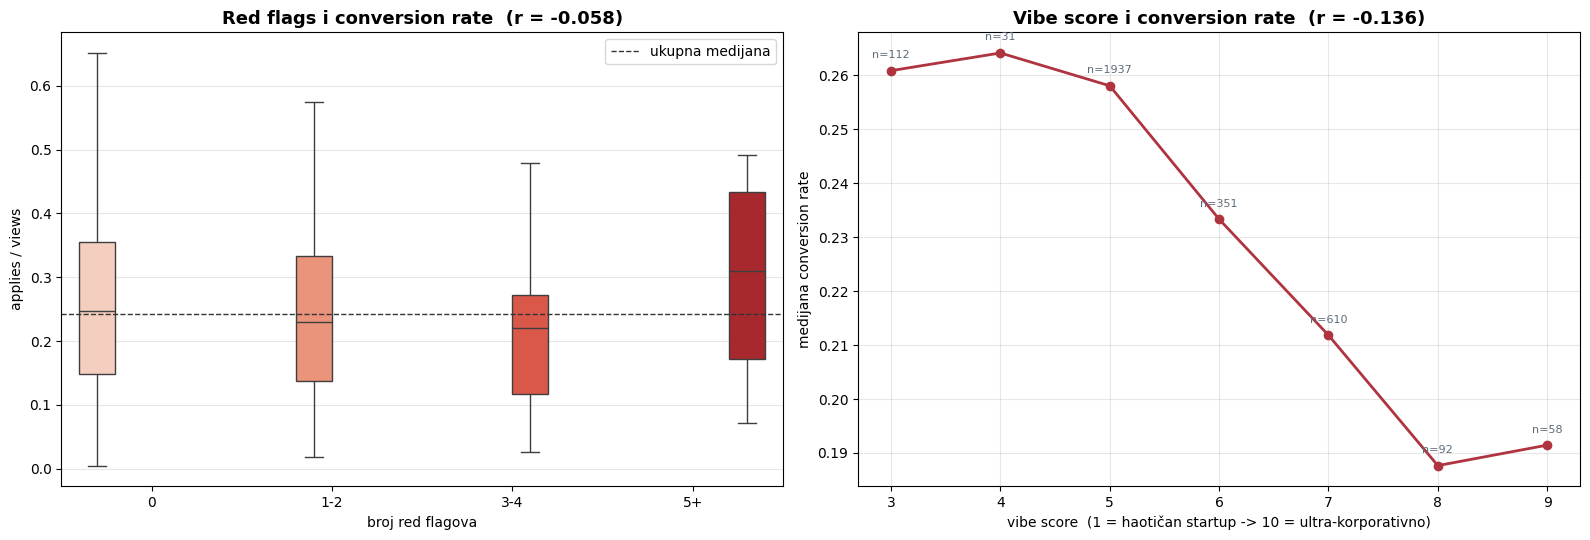

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

ang["red_grupa"] = pd.cut(ang["num_red"], [-1, 0, 2, 4, 99],
                          labels=["0", "1-2", "3-4", "5+"])
sns.boxplot(data=ang, x="red_grupa", y="conversion_rate", hue="red_grupa",
            palette="Reds", legend=False, ax=axes[0], showfliers=False)
axes[0].axhline(ang["conversion_rate"].median(), color="#333", linestyle="--",
                linewidth=1, label="ukupna medijana")
axes[0].set_title(f"Red flags i conversion rate  (r = {r_red:+.3f})",
                  fontsize=13, fontweight="bold")
axes[0].set_xlabel("broj red flagova"); axes[0].set_ylabel("applies / views")
axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)

med_vibe = ang.groupby("vibe_score")["conversion_rate"].agg(["median", "count"])
med_vibe = med_vibe[med_vibe["count"] >= 25]
axes[1].plot(med_vibe.index, med_vibe["median"], marker="o", linewidth=2, color="#AF343F")
for v, red in med_vibe.iterrows():
    axes[1].annotate(f"n={int(red['count'])}", (v, red["median"]),
                     textcoords="offset points", xytext=(0, 9), ha="center",
                     fontsize=8, color="#5C6B7A")
axes[1].set_title(f"Vibe score i conversion rate  (r = {r_vibe:+.3f})",
                  fontsize=13, fontweight="bold")
axes[1].set_xlabel("vibe score  (1 = haotičan startup -> 10 = ultra-korporativno)")
axes[1].set_ylabel("medijana conversion rate"); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG / "ton_prijave.png", dpi=200, bbox_inches="tight")
plt.show()

### Poređenje: ton nasuprot strukturi posla

Korelacije tona su statistički značajne, ali male. Pitanje je koliko su male u
odnosu na nešto drugo, na primer na to kakav je posao u pitanju.

Za to služi Kruskal-Wallisov test, neparametarska alternativa ANOVA-i koja ne
pretpostavlja normalnu raspodelu, a `conversion_rate` je ograničen na opseg od 0
do 1 i iskošen.

In [39]:
po_ulozi = (ang.groupby("role_family")["conversion_rate"]
            .agg(["count", "median"]).round(3)
            .sort_values("median", ascending=False))
print(po_ulozi.to_string())

grupe_uloga = [g["conversion_rate"].values for _, g in ang.groupby("role_family")
               if len(g) >= 30]
h_u, p_u_ = stats.kruskal(*grupe_uloga)

po_nivou = (ang[ang["seniority"].notna()].groupby("seniority", observed=True)["conversion_rate"]
            .agg(["count", "median"]).round(3))
grupe_nivoa = [g["conversion_rate"].values
               for _, g in ang[ang["seniority"].notna()].groupby("seniority", observed=True)
               if len(g) >= 30]
h_n, p_n = stats.kruskal(*grupe_nivoa)

print(f"\n{po_nivou.to_string()}")
print(f"\nKruskal-Wallis po role_family : H = {h_u:.1f}   p = {p_u_:.2e}")
print(f"Kruskal-Wallis po seniority   : H = {h_n:.1f}   p = {p_n:.2e}")
print(f"\nraspon medijana po ulozi: {po_ulozi['median'].min():.3f} - "
      f"{po_ulozi['median'].max():.3f}  "
      f"({(po_ulozi['median'].max()/po_ulozi['median'].min()-1)*100:.0f}% razlike)")

                      count  median
role_family                        
devops_cloud            428   0.273
qa                       79   0.271
data                    926   0.266
software_engineering   1276   0.242
management               16   0.230
non_it                   18   0.200
it_support              250   0.193
security                201   0.184

                  count  median
seniority                      
Internship           28   0.332
Entry level         302   0.225
Associate           258   0.266
Mid-Senior level   1527   0.250
Director             42   0.169
Executive            17   0.218

Kruskal-Wallis po role_family : H = 110.4   p = 3.37e-22
Kruskal-Wallis po seniority   : H = 30.3   p = 1.20e-06

raspon medijana po ulozi: 0.184 - 0.273  (48% razlike)


### Zaključak

Ton ima efekat, ali mali.

| faktor | r | p | ocena |
|---|---:|---:|---|
| vibe score | -0,136 | < 0,0001 | najjača veza u grupi |
| green flags | -0,067 | 0,0001 | značajno, malo |
| red flags | -0,059 | 0,0009 | značajno, malo |
| net flags | -0,055 | 0,0021 | značajno po Pearsonu, po Spearmanu ne (ρ = −0,023, p = 0,20) |

Razlika između oglasa sa crvenim zastavicama i bez njih je statistički značajna,
Welch p = 0,0021, ali je veličina efekta Cohen d = -0,144, dakle mali efekat.
Medijana conversion rate-a je 0,227 kod oglasa sa crvenim zastavicama i 0,247 kod
ostalih.

Struktura posla je znatno jača od tona. Razlika u medijani conversion rate-a
između tipova uloga je 48 %, od 0,184 za `security` do 0,273 za `devops_cloud`,
uz Kruskal-Wallis p = 3,4e-22, nekoliko redova veličine ubedljivije od bilo koje
korelacije tona. Kandidati dakle reaguju pre svega na to kakav je posao, a tek
slabo na to kako je opisan.

Tri ograde.

`vibe_score` je izlaz jezičkog modela, pa zavisi od modela kojim je meren.
Poređenje te ocene između različitih modela nije poređenje istog merenja.

Zelene zastavice su verovatno posredna mera veličine firme i paketa beneficija, a
ne samostalan signal. Razdvajanje bi tražilo model sa kontrolama za veličinu
firme, državu i nivo, kakav se za plate računa u `04_plate.ipynb`.

Uzročnost se ne sme tvrditi. Sve su ovo korelacije nad opservacionim podacima.
Da li crvene zastavice odbijaju kandidate, ili te iste firme privlače manje
kandidata iz drugih razloga, ovi podaci ne razlikuju.

## 15. Zbirna tabela korelacija

Sve mere na jednom mestu, uz p-vrednost i veličinu uzorka za svaku, da bi se
slaba ali stvarna veza mogla razlikovati od šuma.

In [40]:
def red_tabele(x, y, naziv, cilj):
    m = x.notna() & y.notna()
    r, p_r = stats.pearsonr(x[m], y[m])
    rho, _ = stats.spearmanr(x[m], y[m])
    return {"faktor": naziv, "ishod": cilj, "n": int(m.sum()),
            "Pearson r": round(r, 4), "Spearman ρ": round(rho, 4),
            "p": f"{p_r:.4f}" if p_r >= 0.0001 else "<0.0001",
            "značajno": "da" if p_r < 0.05 else "ne"}


sp, an = sa_platom, ang
tabela_kor = pd.DataFrame([
    red_tabele(sp["num_klastera"], sp["godisnja_plata"], "širina znanja (svi)", "plata"),
    red_tabele(bez_nula["num_klastera"], bez_nula["godisnja_plata"], "širina znanja (bez 0)", "plata"),
    red_tabele(sp["num_skills"], sp["godisnja_plata"], "broj tehnologija", "plata"),
    red_tabele(sp["diversity_ratio"], sp["godisnja_plata"], "diversity ratio", "plata"),
    red_tabele(an["num_red"], an["conversion_rate"], "red flags", "conversion"),
    red_tabele(an["num_green"], an["conversion_rate"], "green flags", "conversion"),
    red_tabele(an["net_flags"], an["conversion_rate"], "net flags", "conversion"),
    red_tabele(an["vibe_score"], an["conversion_rate"], "vibe score", "conversion"),
])
print(tabela_kor.to_string(index=False))

tabela_kor.to_csv(INTERIM / "korelacije.csv", index=False)

               faktor      ishod    n  Pearson r  Spearman ρ       p značajno
  širina znanja (svi)      plata 3411     0.1063      0.1361 <0.0001       da
širina znanja (bez 0)      plata 2789     0.1050      0.1297 <0.0001       da
     broj tehnologija      plata 3411     0.0423      0.0782  0.0134       da
      diversity ratio      plata 3060     0.0549      0.0737  0.0024       da
            red flags conversion 3194    -0.0585     -0.0533  0.0009       da
          green flags conversion 3194    -0.0671     -0.0545  0.0001       da
            net flags conversion 3194    -0.0545     -0.0227  0.0021       da
           vibe score conversion 3194    -0.1357     -0.1376 <0.0001       da


### Tri odgovora na tri istraživačka pitanja

Tehnološki ekosistem. 189 tehnologija, 1.260 veza, 14 klastera, Q = 0,640. Šest
velikih klastera odgovara prepoznatljivim oblastima. Postoje dve vrste ključnih
tehnologija: habovi (Python, AWS, Java, SQL), povezani sa gotovo svim oblastima,
i mostovi sa malo veza (Cisco, Active Directory, DB2), koji jednu usku oblast
povezuju sa ostatkom mreže.

Širina znanja i plata. Slaba ali dosledna pozitivna veza, r = +0,106 uz
p < 0,0001, koja preživljava uklanjanje oglasa bez klastera i kontrolu za
seniority. Izraženija je na početku karijere, +0,175 na nivou Entry i +0,240 na
nivou Associate, nego na Mid-Senior nivou, gde iznosi +0,060. Efekat je mali,
oko 1 % objašnjene varijanse, a seniority je neuporedivo jači prediktor.

Ton oglasa. Efekat postoji ali je mali, najviše r = -0,136 za vibe score.
Struktura posla je znatno jača: medijana conversion rate-a se između tipova uloga
razlikuje za 48 %, uz p = 3,4e-22. Kandidati reaguju pre svega na to kakav je
posao, a tek slabo na to kako je opisan.